<a href="https://colab.research.google.com/github/fadilaha/Sentiment-Forecast/blob/main/sentiment_forecast_%2Brandomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment forecasting: XGBoost, LightGBM, VAR, ARIMA, Random Forest

Run the cells from top to bottom. Each model has its own cell (steps 6, 7, 8),
so you can run, change or re-run one model without touching the others.

## 1. Settings

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
PROJECT_DIR = '/content/drive/MyDrive/sentiment_project'   # folder on the Drive
DATA_FOLDER = 'data_csv'               # subfolder containing the monthly files (csv / xlsx)

TIME_COL  = 'Date'           # timestamp column name in the files
LABEL_COL = 'Sentiment'            # sentiment label column name
INPUT_TZ  = 'Asia/Jakarta'         # timezone of the timestamps in the files
LOCAL_TZ  = 'Asia/Jakarta'         # timezone used for binning (WIB)

TARGET     = 'net'                 # 'net' = (pos - neg)/n, or 'share_pos', 'share_neu', 'share_neg'
FREQS      = ['1h', '6h', '12h', '1D']
HORIZONS_H = [1, 6, 12, 24, 72, 168]   # forecast horizons in hours. Horizons: how far the duration of time that will be predicted.
TEST_START = None                  # e.g. '2026-05-01'; None = first day of the last month
FOLD_DAYS  = 3                     # retrain every 3 days during the test period. Every 3 days, the models are retrained from scratch using all the data available up to that point.
MEDIA_COL   = 'Media'              # column with the platform / source
NEWS_VALUES = ['news']             # media value(s) that count as news (lowercase)
OUT_DIR     = 'results_withengagement1'       # new folder, so earlier results are not overwritten

import os
os.chdir(PROJECT_DIR)
print('Working in', os.getcwd(), '| files in data:', sorted(os.listdir(DATA_FOLDER)))

Working in /content/drive/MyDrive/sentiment_project | files in data: ['prabowo26_agustus.csv', 'prabowo26_april.csv', 'prabowo26_juli.csv', 'prabowo26_juni.csv', 'prabowo26_mei.csv']


## 2. Libraries

In [3]:
!pip install -q xgboost lightgbm
import glob, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='X does not have valid feature names')
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 3. Load and merge the monthly files
Check the printout to ensure that every month present, few (to no) unreadable timestamps, and all label values are recognised.

In [4]:
# LOAD AND MERGE THE MONTHLY CSV FILES
LABEL_MAP = {'positive': 1, 'neutral': 0, 'negative': -1}

# columns to read: the ones the models use now + ones that may become features later
# (Text and Link are skipped: they are large and not used as features)
cols = [TIME_COL, LABEL_COL, 'Media', 'Author', 'Followers', 'Retweeted', 'Favourited']

files = sorted(glob.glob(os.path.join(DATA_FOLDER, '*.csv')))
parts = []
for f in files:
    d = pd.read_csv(f, usecols=cols)                 # read only the needed columns (fast)
    print(f'{os.path.basename(f):40s} {len(d):>10,} rows')
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)

# timestamps -> local time (WIB)
t = pd.to_datetime(raw[TIME_COL], errors='coerce', format='mixed')
if t.dt.tz is None:
    t = t.dt.tz_localize(INPUT_TZ, ambiguous='NaT', nonexistent='NaT')
t = t.dt.tz_convert(LOCAL_TZ)

# labels -> +1 / 0 / -1
lab = raw[LABEL_COL].astype(str).str.strip().str.lower().map(LABEL_MAP)

posts = pd.DataFrame({'time': t, 'label': lab})
posts['media']      = raw['Media'].astype(str).str.strip().str.lower()
posts['author']     = raw['Author'].astype(str)
posts['followers']  = pd.to_numeric(raw['Followers'],  errors='coerce').fillna(0)
posts['retweeted']  = pd.to_numeric(raw['Retweeted'],  errors='coerce').fillna(0)
posts['favourited'] = pd.to_numeric(raw['Favourited'], errors='coerce').fillna(0)
if 'MEDIA_COL' in globals():
    posts['media'] = raw[MEDIA_COL].astype(str).str.strip().str.lower()

print(f'\nTotal rows: {len(raw):,} | unreadable timestamps: {t.isna().sum():,} '
      f'| unrecognised labels: {lab.isna().sum():,}')
if lab.isna().any():
    print('  examples of unrecognised labels:', raw.loc[lab.isna(), LABEL_COL].astype(str).unique()[:10])

posts = posts.dropna(subset=['time', 'label'])
posts['label'] = posts['label'].astype(int)
del raw, parts, t, lab

# quick checks
print(f'Kept {len(posts):,} posts, {posts.time.min()} -> {posts.time.max()}')
print('\nPosts per month:')
print(posts.time.dt.tz_localize(None).dt.to_period('M').value_counts().sort_index().to_string())
print('\nLabels:', posts.label.map({1: 'positive', 0: 'neutral', -1: 'negative'}).value_counts().to_dict())
if 'media' in posts:
    print('\nPosts per media:')
    print(posts.media.value_counts(normalize=True).round(3).to_string())
print('\nPosts by hour of day (should be low at night if the timezone is right):')
print(posts.time.dt.hour.value_counts().sort_index().to_string())

prabowo26_agustus.csv                       330,158 rows
prabowo26_april.csv                         257,472 rows
prabowo26_juli.csv                          323,615 rows
prabowo26_juni.csv                          409,684 rows
prabowo26_mei.csv                           342,500 rows

Total rows: 1,663,429 | unreadable timestamps: 0 | unrecognised labels: 0
Kept 1,663,429 posts, 2026-04-01 00:00:00+07:00 -> 2026-08-31 23:59:28+07:00

Posts per month:
time
2026-04    257472
2026-05    342500
2026-06    409684
2026-07    323615
2026-08    330158
Freq: M

Labels: {'negative': 805823, 'positive': 672424, 'neutral': 185182}

Posts per media:
media
twitter      0.563
news         0.296
youtube      0.059
instagram    0.055
tiktok       0.011
facebook     0.009
threads      0.007

Posts by hour of day (should be low at night if the timezone is right):
time
0     56761
1     39423
2     30632
3     25404
4     30646
5     48242
6     62363
7     77898
8     81703
9     81386
10    85717
11    

## 4. Group posts into time bins

The posts's sentiment is counted (Positive-Negative/N) per hour, per 6 hours, per 12 hours, and per day. The graph shown in this cell is the actual data from January to September. The part that will be predicted and tested is the start of September (marked by dashed line).

  1h:  3,624 bins | posts per bin: median 423, min 0 | empty bins 0.2%
  6h:    604 bins | posts per bin: median 2550, min 351 | empty bins 0.0%
 12h:    302 bins | posts per bin: median 5024, min 1916 | empty bins 0.0%
  1D:    151 bins | posts per bin: median 10274, min 4340 | empty bins 0.0%

Training data: before 2026-08-01 | test: 2026-08-01 onwards


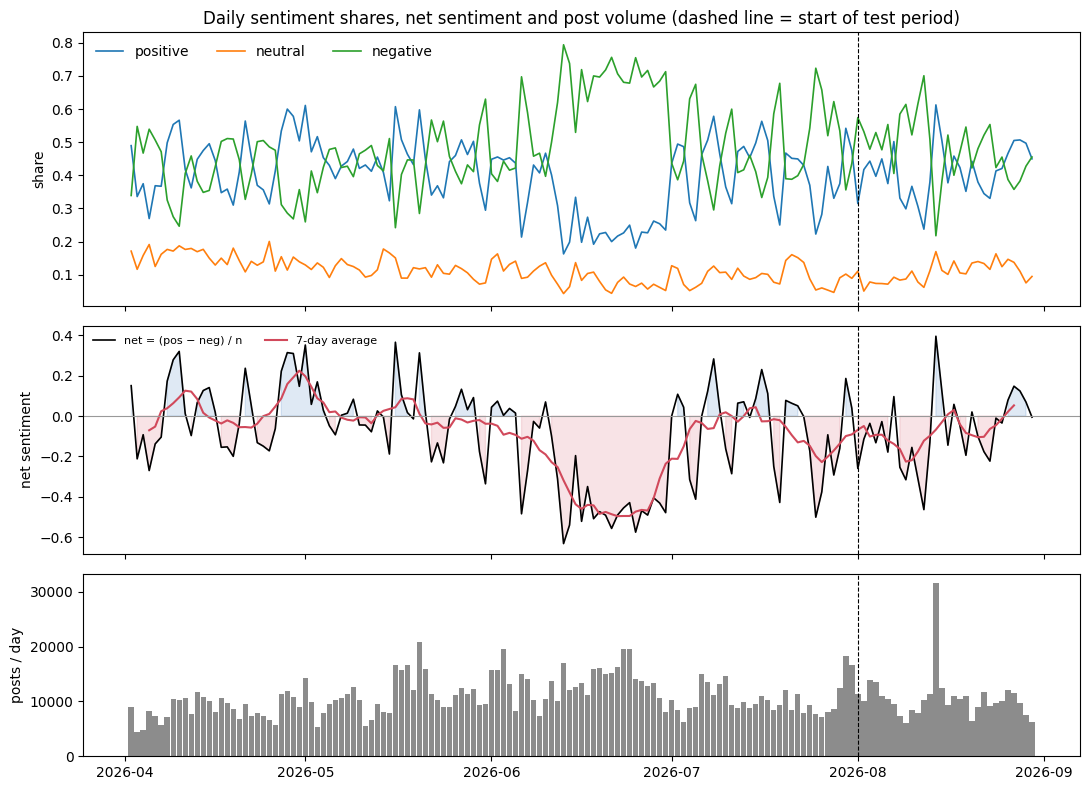

In [5]:
FREQ_HOURS = {'1h': 1, '3h': 3, '6h': 6, '12h': 12, '1d': 24}

def aggregate(posts, freq):
    start = posts.time.min().normalize() + pd.Timedelta(days=1)   # complete days only
    end = posts.time.max().normalize()
    p = posts[(posts.time >= start) & (posts.time < end)]
    counts = p.groupby([pd.Grouper(key='time', freq=freq), 'label']).size().unstack(fill_value=0)
    idx = pd.date_range(start, end, freq=freq, inclusive='left')
    counts = counts.reindex(idx, fill_value=0)
    for k in (-1, 0, 1):
        if k not in counts.columns:
            counts[k] = 0
    a = pd.DataFrame(index=idx)
    a['n_neg'], a['n_neu'], a['n_pos'] = counts[-1], counts[0], counts[1]
    a['n'] = a[['n_neg', 'n_neu', 'n_pos']].sum(axis=1)
    nz = a['n'].replace(0, np.nan)
    a['share_pos'], a['share_neu'], a['share_neg'] = a.n_pos / nz, a.n_neu / nz, a.n_neg / nz
    a['net'] = (a.n_pos - a.n_neg) / nz
    a['is_empty'] = (a.n == 0).astype(int)
    c = ['share_pos', 'share_neu', 'share_neg', 'net']
    # Carry forward the latest observed sentiment for empty bins.
    # Remove leading bins that have no previous sentiment observation.
    a[c] = a[c].ffill()
    a = a.dropna(subset=c)
    a['logn'] = np.log1p(a.n)
    return a

os.makedirs(OUT_DIR, exist_ok=True)
AGGS = {}
for fq in FREQS:
    AGGS[fq] = aggregate(posts, fq)
    AGGS[fq].to_csv(f'{OUT_DIR}/aggregated_{fq}.csv', index_label='bin_start')
    a = AGGS[fq]
    print(f'{fq:>4}: {len(a):6,} bins | posts per bin: median {a.n.median():.0f}, '
          f'min {a.n.min():.0f} | empty bins {a.is_empty.mean():.1%}')

if TEST_START:
    TEST_START_TS = pd.Timestamp(TEST_START, tz=LOCAL_TZ)
else:
    last = posts.time.max()
    TEST_START_TS = pd.Timestamp(year=last.year, month=last.month, day=1, tz=LOCAL_TZ)
print(f'\nTraining data: before {TEST_START_TS.date()} | test: {TEST_START_TS.date()} onwards')

d = aggregate(posts, '1D')
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                       gridspec_kw={'height_ratios': [1.2, 1, 0.8]})
for c, l in (('share_pos', 'positive'), ('share_neu', 'neutral'), ('share_neg', 'negative')):
    ax[0].plot(d.index, d[c], label=l, lw=1.2)
ax[0].set_ylabel('share'); ax[0].legend(frameon=False, ncol=3)
ax[0].set_title('Daily sentiment shares, net sentiment and post volume (dashed line = start of test period)')
ax[1].plot(d.index, d.net, color='k', lw=1.2, label='net = (pos − neg) / n')
ax[1].plot(d.index, d.net.rolling(7, center=True).mean(), color='#d1495b', lw=1.5,
           label='7-day average')
ax[1].fill_between(d.index, 0, d.net, where=d.net >= 0, color='#2a6fbb', alpha=0.15)
ax[1].fill_between(d.index, 0, d.net, where=d.net < 0, color='#d1495b', alpha=0.15)
ax[1].axhline(0, color='0.6', lw=0.8)
ax[1].set_ylabel('net sentiment'); ax[1].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
ax[2].bar(d.index, d.n, width=0.9, color='0.55'); ax[2].set_ylabel('posts / day')
for a in ax:
    a.axvline(TEST_START_TS, color='k', ls='--', lw=0.8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/series_daily.png', dpi=140); plt.show()

In [6]:
import numpy as np, pandas as pd
TRAIN_END = '2026-08-31'
fq   = '1h'
TRAIN_END_TS = pd.Timestamp('2026-08-01', tz='Asia/Jakarta')
y    = AGGS[fq].loc[:TRAIN_END, 'net']
LAGS = [1, 2, 3, 6, 12, 24, 48, 72, 168]      # dalam satuan bin (1h)
HS   = [1, 6, 24, 72, 168]                     # horizon dalam bin

out = {}
for h in HS:
    target = y.shift(-h) - y                   # target model: perubahan h langkah ke depan
    row = {}
    for k in LAGS:
        d = pd.DataFrame({'t': target, 'y0': y, 'lag': y.shift(k)}).dropna()
        # buang pengaruh y[t] dari target dan dari lag, lalu korelasikan sisanya
        rt = d.t   - np.polyval(np.polyfit(d.y0, d.t,   1), d.y0)
        rl = d.lag - np.polyval(np.polyfit(d.y0, d.lag, 1), d.y0)
        row[k] = np.corrcoef(rt, rl)[0, 1]
    out[f'h={h}'] = row

tab = pd.DataFrame(out)
tab.index.name = 'lag'
display(tab.round(3))

,h=1,h=6,h=24,h=72,h=168
lag,,,,,
1,0.191,0.071,0.144,0.086,0.116
2,0.217,0.032,0.145,0.076,0.110
3,0.108,0.018,0.123,0.071,0.094
6,0.071,0.031,0.000,-0.025,-0.007
12,0.035,0.230,-0.067,-0.089,-0.103
24,0.146,0.002,0.190,0.200,0.161
48,0.092,-0.045,0.188,0.246,0.153
72,0.086,-0.027,0.201,0.298,0.147
168,0.114,-0.009,0.154,0.141,0.177


In [7]:
#MENGUJI APAKAH JUMLAH ENGAGEMENT MEMILIKI PENGARUH KE SENTIMEN
import numpy as np, pandas as pd

fq, bh = '1h', 1                          # ganti ke '1D', 24 untuk cek bin harian
TRAIN_END_TS = pd.Timestamp('2026-08-01', tz='Asia/Jakarta')
p = posts[posts.time < TRAIN_END_TS].copy()

p['eng'] = p['retweeted'].fillna(0) + p['favourited'].fillna(0)
p['w_lab'] = p['label'] * p['eng']
thr = p['followers'].quantile(0.99)       # batas akun besar (top 1%)
big = p[p['followers'] >= thr]

g = p.groupby(pd.Grouper(key='time', freq=fq))
feat = pd.DataFrame({
    'y':       g.label.mean(),                               # net sentiment
    'log_eng': np.log1p(g.eng.sum()),
    'eng_net': g.w_lab.sum() / g.eng.sum().replace(0, np.nan),
    'big_net': big.groupby(pd.Grouper(key='time', freq=fq)).label.mean(),
}).ffill()

out = {}
for col in ['log_eng', 'eng_net', 'big_net']:
    row = {}
    for h in [1, 6, 24, 72, 168]:
        k = h // bh
        if k == 0: continue
        d = pd.DataFrame({'t': feat.y.shift(-k) - feat.y, 'y0': feat.y,
                          'x': feat[col].shift(24 // bh if bh < 24 else 1)}).dropna()  # jeda 1 hari
        rt = d.t - np.polyval(np.polyfit(d.y0, d.t, 1), d.y0)
        rx = d.x - np.polyval(np.polyfit(d.y0, d.x, 1), d.y0)
        row[f'h={h}'] = np.corrcoef(rt, rx)[0, 1]
    out[col] = row
display(pd.DataFrame(out).T.round(3))

,h=1,h=6,h=24,h=72,h=168
log_eng,0.158,0.006,0.227,0.273,0.163
eng_net,0.049,-0.045,0.093,0.089,0.024
big_net,-0.000,-0.005,0.009,0.071,0.016


In [8]:
fq, bh = '1h', 1
bpd = 24 // bh
g = p.groupby(pd.Grouper(key='time', freq=fq))
df = pd.DataFrame({
    'y':       g.label.mean(),
    'logn':    np.log1p(g.size()),
    'log_eng': np.log1p(g.eng.sum()),
}).ffill()
hour = df.index.hour
df['hs'], df['hc'] = np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24)

print('korelasi log_eng vs logn:', round(df.log_eng.corr(df.logn), 3))

def partial_r(target, x, controls):
    d = pd.concat([target.rename('t'), x.rename('x'), controls], axis=1).dropna()
    C = np.column_stack([np.ones(len(d)), d[controls.columns].to_numpy()])
    rt = d.t - C @ np.linalg.lstsq(C, d.t, rcond=None)[0]
    rx = d.x - C @ np.linalg.lstsq(C, d.x, rcond=None)[0]
    return np.corrcoef(rt, rx)[0, 1]

controls = pd.DataFrame({
    'y0':       df.y,
    'y_lag24':  df.y.shift(bpd),
    'logn_lag': df.logn.shift(bpd),
    'hs': df.hs, 'hc': df.hc,
})
res = {}
for h in [1, 6, 24, 72, 168]:
    k = h // bh
    res[f'h={h}'] = partial_r(df.y.shift(-k) - df.y, df.log_eng.shift(bpd), controls)
print(pd.Series(res).round(3))

korelasi log_eng vs logn: 0.354
h=1      0.096
h=6      0.085
h=24     0.145
h=72     0.184
h=168    0.041
dtype: float64


In [9]:
#MENGHITUNG DATA ENGAGEMENT PER BIN
def add_engagement(agg, freq):
    e = posts.assign(eng=posts['retweeted'].fillna(0) + posts['favourited'].fillna(0))
    s = e.groupby(pd.Grouper(key='time', freq=freq)).eng.sum()
    agg = agg.copy()
    agg['log_eng'] = np.log1p(s.reindex(agg.index, fill_value=0))
    return agg

for fq in AGGS:
    AGGS[fq] = add_engagement(AGGS[fq], fq)

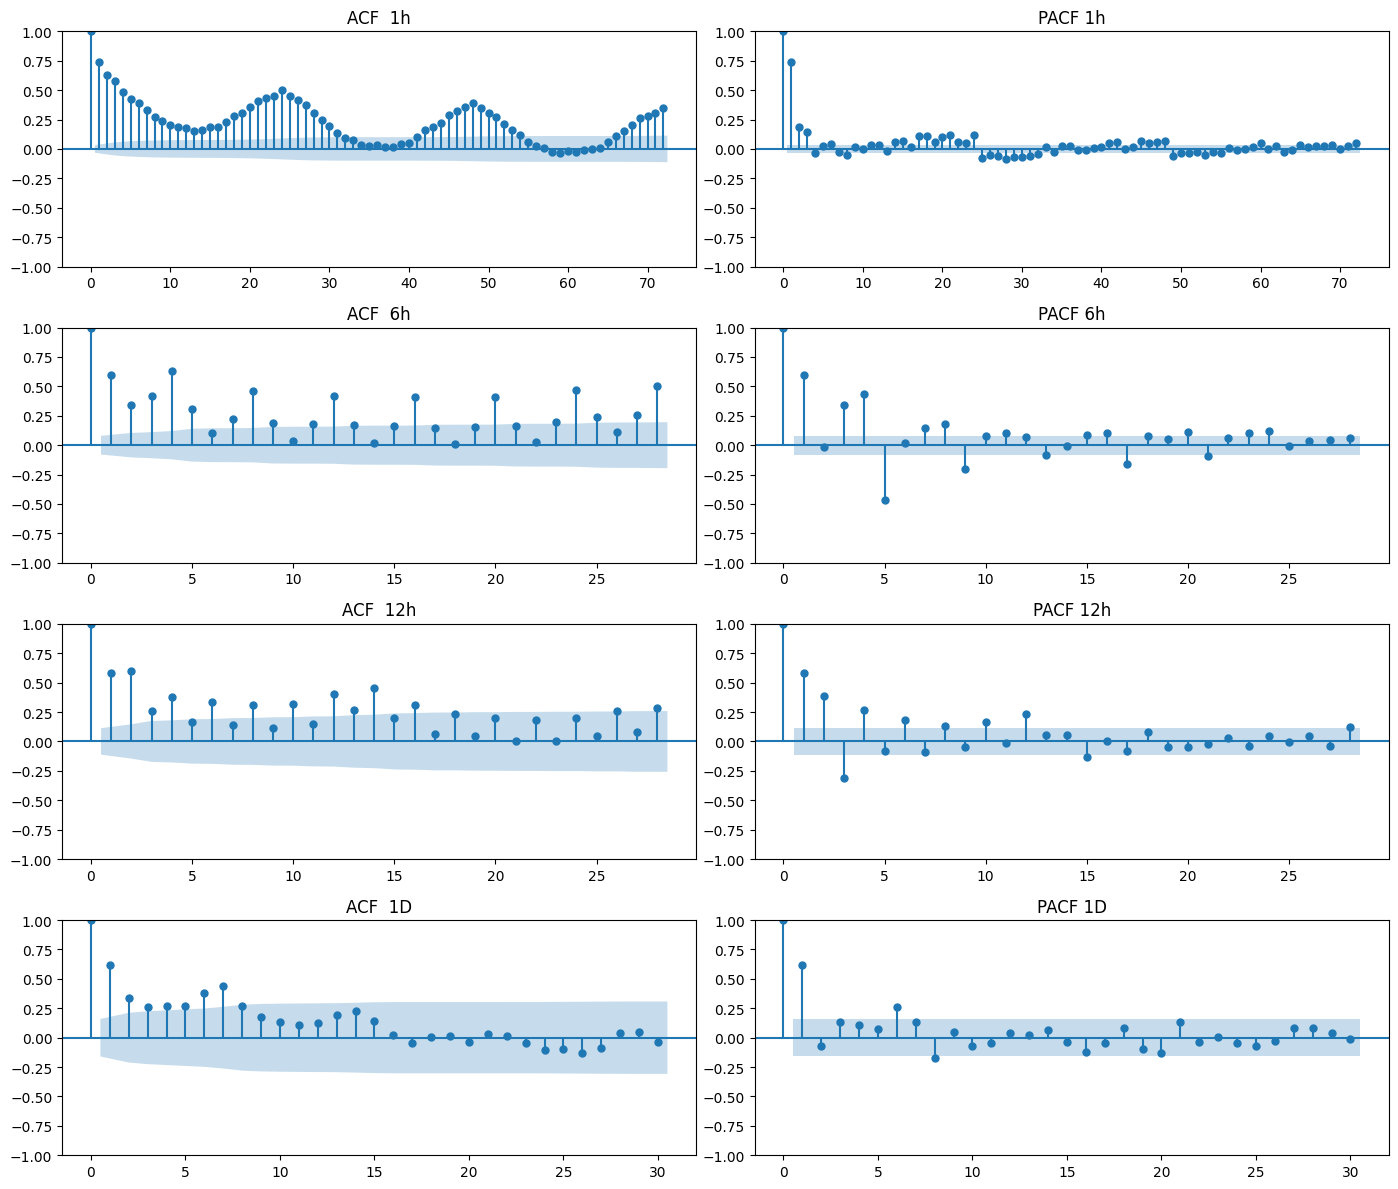

In [10]:
#UJI ACF DAN PACF untuk decide potensi rentang p dan q
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

TRAIN_END = '2026-08-31'
N_LAGS = {'1h': 72, '6h': 28, '12h': 28, '1D': 30}   # ~3 hari untuk 1h, ~1-2 minggu untuk lainnya

fig, axes = plt.subplots(4, 2, figsize=(14, 12))
for i, fq in enumerate(['1h', '6h', '12h', '1D']):
    y = AGGS[fq].loc[:TRAIN_END, 'net'].dropna()     # ganti 'net' kalau nama kolomnya beda
    plot_acf(y,  lags=N_LAGS[fq], ax=axes[i][0], title=f'ACF  {fq}')
    plot_pacf(y, lags=N_LAGS[fq], ax=axes[i][1], title=f'PACF {fq}', method='ywm')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/acf_pacf.png', dpi=150)
plt.show()

## **Preparation: features engineering, test weeks and comparison to naive forecast**
**Nothing is predicted in this cell.** It prepares everything the model cells (6, 7, 8) need. It has four jobs.

### Job 1: build the features (the models' inputs)
A model can't read a raw sentiment line. It needs a **table**: one row per moment in time, one column per
piece of information that is already known at that moment. Example row for 13 September 20:00 (row are the time, columns are features):

| Feature | Meaning |
|---|---|
| `y_lag0` | net sentiment now |
| `y_lag1`, `y_lag2` | net sentiment 1 and 2 bins ago |
| `y_mean24` | average net over the last 24 bins |
| `y_std_day` | how much net jumped around during the last day (volatility) |
| `y_dev_week` | how far net is from its 7-day average |
| `share_pos`, `share_neu`, `share_neg` | the shares now (except the one being forecast) |
| `logn` | how many posts there are now (log scale) |
| `logn_surge` | is volume unusually high vs the last 7 days? (**event signal**) |
| `hour_sin/cos`, `dow_sin/cos` | time of day and day of week (as a circle, so 23:00 is close to 00:00) |

XGBoost and LightGBM learn from this table. VAR (cell 8) uses the raw series directly.

### Job 2: set up the test weeks (folds)
The test period (from `TEST_START`) is cut into blocks of `FOLD_DAYS` (7) days. Before each block, the models are retrained on all data before that block, so September data is added as it "arrives":

| Fold | Trained on | Forecasts for |
|---|---|---|
| 1 | 1 Jan – 31 Aug | 1 – 7 Sep |
| 2 | 1 Jan – 7 Sep | 8 – 14 Sep |
| … | … | … |

A model is never allowed to see the value it is forecasting (no "future leakage").

### Job 3: build the "no change" yardstick
For every moment in the test period it records the simplest possible forecast: **the future = the value now.** It is also called the *persistence* or *naive* forecast.
**Why is it needed?** An error number alone means nothing. If XGBoost's average error (MAE) is 0.08, is that good?
We can't tell without something to compare it with. The fairest comparison is the simplest thing to do without a model, **assume nothing changes**. Sentiment usually changes slowly, so "same as now" is often close. That makes it an honest benchmark.

### Job 4: define helper tools used later
* `run_tree_model`: trains XGBoost / LightGBM fold by fold (used in cells 6 and 7)
* `score`: compares a model with "no change"
* `show`: prints the skill table

### How to read **skill** (comparison of model result and 'no change' assumption)
**skill = 1 − (model error ÷ "no change" error)**

| Skill | Meaning |
|---|---|
| 0.30 | the model's error is 30 % smaller than "no change", so it's useful |
| 0 | no better than copying the current value |
| below 0 | **worse** than copying the current value, so the model hurts |

Example from this data: XGBoost with daily bins, 24 h ahead, had skill −0.03, so it was worse than simply copying today's value. Without the yardstick that would have looked like a normal error number.

In [11]:
# FEATURE 1: LAG FEATURES
# Capture past sentiment values at selected time intervals.
# These features help the model recognize temporal dependencies
# without requiring the entire time series as a sequence.

def build_lag_features(agg, hours):

    # Number of time bins in one day and one week
    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Selected historical positions:
    # Current value, 1 and 3 bins ago, approximately 1 day ago,
    # 3 days ago, and 1 week ago
    lag_steps = sorted({
        0, 1, 6,
        bins_per_day,
        3 * bins_per_day,
        bins_per_week
    })
    for lag in lag_steps:
        f[f'y_lag{lag}'] = y.shift(lag)

    return f

In [12]:
# FEATURE 2: ROLLING MEAN FEATURES
# Calculate the average sentiment over recent time windows.
# These features help the model identify short-term and
# long-term sentiment trends while reducing short-term fluctuations.

def build_rolling_mean_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Rolling windows: last 3 bins (excluded), 1 day, and 1 week
    windows = sorted({bins_per_day, bins_per_week})

    for window in windows:
        if window >= 2:
            f[f'y_mean{window}'] = y.rolling(window).mean()

    return f

In [13]:
# FEATURE 3: SENTIMENT VOLATILITY AND CHANGE FEATURES
# Capture how much sentiment fluctuates, how fast it changes,
# and how far the current sentiment deviates from its recent average.

def build_sentiment_dynamics_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # 1. Daily volatility (standard deviation)
    # At least 3 bins are used to calculate volatility.
    f['y_std_recent'] = y.rolling(max(bins_per_day, 3)).std()

    # 2. First difference: change from the previous time bin
    f['y_diff1'] = y.diff()

    # 3. Deviation from the rolling weekly average
    #f['y_dev_week'] = y - y.rolling(bins_per_week).mean()

    return f

In [14]:
# FEATURE 4: SENTIMENT COMPOSITION FEATURES
# Include the current shares of positive, neutral, and negative sentiment.
# This provides additional information about sentiment composition
# beyond the main target variable.

def build_sentiment_share_features(agg):

    f = pd.DataFrame(index=agg.index)

    for col in ('share_pos', 'share_neu', 'share_neg'):
        if col != TARGET:
            f[col] = agg[col]

    return f

In [15]:
# FEATURE 5: POST VOLUME FEATURES
# Capture the current discussion volume, unusual increases in activity,
# and changes in the number of posts over time.

def build_volume_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    logn = agg['logn']
    f = pd.DataFrame(index=agg.index)

    # Current post volume (log-transformed)
    f['logn'] = logn

    # Difference between current volume and its weekly average.
    # Positive values indicate higher activity than the recent baseline.
    f['logn_surge'] = logn - logn.rolling(bins_per_week).mean()

    # Change in post volume from the previous time bin
    f['logn_diff1'] = logn.diff()

    # Indicator for time bins with no posts
    f['is_empty'] = agg['is_empty']

    return f

In [16]:
# FEATURE 6: CALENDAR FEATURES (FOURIER TERMS)
# Represent time as cyclical variables using sine and cosine transformations.
# This allows the model to recognize periodic patterns, such as daily
# and weekly sentiment differences.

def build_calendar_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    f = pd.DataFrame(index=agg.index)

    # Hour of day: only applicable to sub-daily time bins
    if bins_per_day > 1:

        hour = agg.index.hour + agg.index.minute / 60

        f['hour_sin'] = np.sin(2 * np.pi * hour / 24)
        f['hour_cos'] = np.cos(2 * np.pi * hour / 24)

    # Day of week: Monday = 0, Sunday = 6
    day_of_week = agg.index.dayofweek

    f['dow_sin'] = np.sin(2 * np.pi * day_of_week / 7)
    f['dow_cos'] = np.cos(2 * np.pi * day_of_week / 7)

    return f

In [17]:
# FEATURE 7: ENGAGEMENT FEATURES
# Total retweets + likes per bin, shifted by 1 day because engagement keeps growing
# after a post is published (avoids using information from after the forecast origin).
def build_engagement_features(agg, hours):
    bpd = max(1, 24 // hours)
    f = pd.DataFrame(index=agg.index)
    le = agg['log_eng']
    f['log_eng_lag1d']   = le.shift(bpd)
    f['log_eng_surge1d'] = (le - le.rolling(7 * bpd).mean()).shift(bpd)
    return f

In [18]:
# FEATURE 8: EXOGENOUS FEATURES (from outside the sentiment series)
# 1. News coverage    : number of news articles per bin (media agenda / events)
# 2. Platform mix     : share of posts from each platform (Twitter, YouTube, ...)
# 3. Calendar flags   : weekend, active hours (day/night), national holiday
# News and platform values are only known once a bin has happened, so they are used
# as values "up to now" (current bin and earlier) -> no future leakage.
# Calendar flags are known in advance.

# --- 1. add media counts per bin to every aggregated table -----------------------
def add_media_counts(agg, freq):
    c = (posts.groupby([pd.Grouper(key='time', freq=freq), 'media'])
              .size().unstack(fill_value=0))
    c = c.reindex(agg.index, fill_value=0)
    c.columns = ['m_' + str(col).replace(' ', '_') for col in c.columns]
    return agg.drop(columns=[x for x in agg.columns if x.startswith('m_')]).join(c)

for fq in AGGS:
    AGGS[fq] = add_media_counts(AGGS[fq], fq)

# media values counted as "news", and platforms with at least 1% of all posts
NEWS_COLS = ['m_' + v.replace(' ', '_') for v in NEWS_VALUES]
media_share = posts['media'].value_counts(normalize=True)
PLATFORM_COLS = ['m_' + str(v).replace(' ', '_') for v, s in media_share.items()
                 if s >= 0.01 and v not in NEWS_VALUES]
print('News columns    :', [c for c in NEWS_COLS if c in AGGS[FREQS[0]].columns])
print('Platform columns:', PLATFORM_COLS)

# --- national holidays (Indonesia) -------------------------------------------------
try:
    import holidays
    years = sorted(posts.time.dt.year.unique())
    HOLIDAY_DATES = pd.DatetimeIndex(sorted(holidays.Indonesia(years=years).keys()))
    print(f'{len(HOLIDAY_DATES)} Indonesian public holidays loaded')
except Exception as e:
    HOLIDAY_DATES = pd.DatetimeIndex([])
    print('holidays package not available -> holiday flag set to 0 (pip install holidays)')


# --- 2. the feature function -------------------------------------------------------
def build_exogenous_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    f = pd.DataFrame(index=agg.index)
    n = agg['n'].clip(lower=1)

    # Platform mix
    for col in PLATFORM_COLS:
        if col in agg.columns:
            f['plat_' + col[2:]] = agg[col] / n

    # Calendar flags (known in advance)
    f['is_weekend'] = (agg.index.dayofweek >= 5).astype(int)
    if bins_per_day > 1:                                   # day/night only for sub-daily bins
        f['is_active_hours'] = ((agg.index.hour >= 6) & (agg.index.hour < 22)).astype(int)
    days = agg.index.tz_localize(None).normalize()
    f['is_holiday'] = days.isin(HOLIDAY_DATES).astype(int)

    return f

News columns    : ['m_news']
Platform columns: ['m_twitter', 'm_youtube', 'm_instagram', 'm_tiktok']
17 Indonesian public holidays loaded


In [19]:
# FEATURE 9: COMBINE ALL FEATURES
# Combine all feature groups into a single DataFrame.
# Each row represents one time bin, while each column represents
# one feature describing the information available at that time.

def build_features(agg, hours):

    features = [
        build_lag_features(agg, hours),
        build_rolling_mean_features(agg, hours),
        #build_sentiment_dynamics_features(agg, hours),
        #build_sentiment_share_features(agg),
        build_volume_features(agg, hours),
        build_calendar_features(agg, hours),
        build_engagement_features(agg, hours),
        #build_exogenous_features(agg, hours)
    ]

    # Combine all feature groups column-wise
    f = pd.concat(features, axis=1)

    return f

The output of feature engineering is a DataFrame in which each row represents one time bin and each column represents an engineered feature. Each row therefore contains information available at a particular timestamp, including historical sentiment, recent trends, volatility, sentiment composition, post volume, and temporal patterns. The DataFrame is subsequently converted into a NumPy array to serve as the input feature matrix for machine learning models.

In [20]:
# INSPECT FEATURE ENGINEERING OUTPUT
# Ensure the produced features are matched with our expectation
# Example using 6-hour aggregated data
example_agg = AGGS['6h']

feats = build_features(
    example_agg,
    FREQ_HOURS['6h']
)

print("Feature matrix shape:", feats.shape)
print("\nFeature names:")
print(feats.columns.tolist())

print("\nFeature matrix preview:")
display(feats.head())

Feature matrix shape: (604, 18)

Feature names:
['y_lag0', 'y_lag1', 'y_lag4', 'y_lag6', 'y_lag12', 'y_lag28', 'y_mean4', 'y_mean28', 'logn', 'logn_surge', 'logn_diff1', 'is_empty', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'log_eng_lag1d', 'log_eng_surge1d']

Feature matrix preview:


,y_lag0,y_lag1,y_lag4,y_lag6,y_lag12,y_lag28,y_mean4,y_mean28,logn,logn_surge,logn_diff1,is_empty,hour_sin,hour_cos,dow_sin,dow_cos,log_eng_lag1d,log_eng_surge1d
2026-04-02 00:00:00+07:00,0.130191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.793466,NaN,NaN,0,0.000000e+00,1.000000e+00,0.433884,-0.900969,NaN,NaN
2026-04-02 06:00:00+07:00,0.212211,0.130191,NaN,NaN,NaN,NaN,NaN,NaN,8.016648,NaN,1.223182,0,1.000000e+00,6.123234e-17,0.433884,-0.900969,NaN,NaN
2026-04-02 12:00:00+07:00,0.158507,0.212211,NaN,NaN,NaN,NaN,NaN,NaN,7.951559,NaN,-0.065089,0,1.224647e-16,-1.000000e+00,0.433884,-0.900969,NaN,NaN
2026-04-02 18:00:00+07:00,0.062098,0.158507,NaN,NaN,NaN,NaN,0.140752,NaN,7.684784,NaN,-0.266775,0,-1.000000e+00,-1.836970e-16,0.433884,-0.900969,NaN,NaN
2026-04-03 00:00:00+07:00,-0.043478,0.062098,0.130191,NaN,NaN,NaN,0.097334,NaN,6.469250,NaN,-1.215534,0,0.000000e+00,1.000000e+00,-0.433884,-0.900969,14.233441,NaN


In [21]:
# DATASET PREPARATION
# Build the feature matrix, target series, sample weights,
# and forecasting horizons for each time frequency.
# All datasets are stored in DATA[freq], e.g. DATA['6h'].

DATA = {}

for fq, agg in AGGS.items():

    hours = FREQ_HOURS[fq.lower()]

    # Build the feature DataFrame
    feats = build_features(agg, hours)

    # Convert features into a numerical matrix for model input
    X = feats.to_numpy(dtype=float)

    # Target variable to be forecast
    y = agg[TARGET].to_numpy(dtype=float)

    # Store timestamps
    times = agg.index

    # Exclude rows containing missing feature values
    # Missing values mainly occur at the beginning of the series
    # because rolling windows and lag features require historical data.
    valid = ~np.isnan(X).any(axis=1)

    # Assign sample weights based on post volume.
    # Bins with more posts receive higher training weights.
    w = np.sqrt(np.clip(agg.n.to_numpy(dtype=float), 1, None))
    w /= w.mean()

    # Convert forecasting horizons from hours into time-bin steps.
    # Only horizons that match the selected bin frequency are retained.
    steps = [
        h // hours
        for h in HORIZONS_H
        if h % hours == 0 and h >= hours
    ]

    # Store all information for this frequency
    DATA[fq] = dict(
        agg=agg,
        hours=hours,
        X=X,
        features=feats,
        feature_names=list(feats.columns),
        y=y,
        w=w,
        valid=valid,
        times=times,
        T=len(agg),
        steps=steps
    )

    print(
        f'{fq:>4}: {X.shape[0]} time bins, '
        f'{X.shape[1]} features, '
        f'horizons (steps): {steps}'
    )

  1h: 3624 time bins, 18 features, horizons (steps): [1, 6, 12, 24, 72, 168]
  6h: 604 time bins, 18 features, horizons (steps): [1, 2, 4, 12, 28]
 12h: 302 time bins, 17 features, horizons (steps): [1, 2, 6, 14]
  1D: 151 time bins, 14 features, horizons (steps): [1, 3, 7]


In [22]:
# TEMPORAL TEST SPLITTING
# Divide the test period into consecutive time blocks (folds).
# Each fold represents a period to be evaluated.
# As the test period moves forward, additional historical data
# becomes available for model retraining.

for fq, D in DATA.items():

    times = D['times']
    valid = D['valid']
    T = D['T']

    folds = []

    for fold_start in pd.date_range(
        TEST_START_TS,
        times[-1],
        freq=f'{FOLD_DAYS}D'
    ):

        # Identify valid forecasting origins within the current test fold
        in_fold = (
            (times >= fold_start) &
            (times < fold_start + pd.Timedelta(days=FOLD_DAYS))
        )

        test_origins = np.where(in_fold & valid)[0]

        # First time bin that cannot be used as a training target
        train_end = int(np.searchsorted(times, fold_start))

        if len(test_origins) > 0:
            folds.append(
                (fold_start, test_origins, train_end)
            )

    D['folds'] = folds

    print(f'{fq:>4}: {len(folds)} test folds created')

  1h: 10 test folds created
  6h: 10 test folds created
 12h: 10 test folds created
  1D: 10 test folds created


In [23]:
# STATIONARITY TEST (ADF)
from statsmodels.tsa.stattools import adfuller

def adf_test(series):
    series = pd.Series(series).dropna()

    result = adfuller(series, autolag='AIC')

    return {
        'ADF statistic': result[0],
        'p-value': result[1],
        'stationary': result[1] < 0.05
    }

ADF_ROWS = []

for fq, D in DATA.items():

    # Use only the first fold's training data
    _, _, train_end = D['folds'][0]

    agg = D['agg']

    # Variables used by VAR
    var_series = {
        'net': agg['net'].iloc[:train_end],
        'share_pos': agg['share_pos'].iloc[:train_end],
        'share_neg': agg['share_neg'].iloc[:train_end],
        'logn': np.log1p(agg['n'].iloc[:train_end])
    }

    for name, series in {**var_series}.items():

        result = adf_test(series)

        ADF_ROWS.append({
            'frequency': fq,
            'variable': name,
            **result
        })

ADF_RESULTS = pd.DataFrame(ADF_ROWS)

display(ADF_RESULTS.round(4))

,frequency,variable,ADF statistic,p-value,stationary
0,1h,net,-4.9816,0.0000,True
1,1h,share_pos,-5.1194,0.0000,True
2,1h,share_neg,-4.8360,0.0000,True
3,1h,logn,-5.8320,0.0000,True
4,6h,net,-2.5588,0.1018,False
5,6h,share_pos,-2.6939,0.0751,False
6,6h,share_neg,-2.4557,0.1266,False
7,6h,logn,-3.4866,0.0083,True
8,12h,net,-1.9113,0.3268,False
9,12h,share_pos,-2.0108,0.2818,False


In [24]:
# PERSISTENCE BASELINE
# Create a naive forecasting baseline.
# Assumption: future sentiment will remain equal to the current sentiment.
# Forecast: y(t + h) = y(t)

def to_frame(name, fq, s, origins, y_true, y_pred):

    D = DATA[fq]

    return pd.DataFrame(dict(
        model=name,
        freq=fq,
        horizon_h=s * D['hours'],
        origin=origins,
        origin_time=D['times'][origins],
        y_true=y_true,
        y_pred=y_pred
    ))


rows = []

for fq, D in DATA.items():

    for fold_start, test_origins, train_end in D['folds']:

        for s in D['steps']:

            # Exclude forecasts that extend beyond the available data
            origins = test_origins[
                test_origins + s < D['T']
            ]

            # Actual future sentiment
            y_true = D['y'][origins + s]

            # Persistence prediction: future sentiment = current sentiment
            y_pred = D['y'][origins]

            rows.append(
                to_frame(
                    'persistence',
                    fq,
                    s,
                    origins,
                    y_true,
                    y_pred
                )
            )


# Store all baseline forecasts in PRED
PRED = {
    'persistence': pd.concat(rows, ignore_index=True)
}

print(
    'Persistence baseline created:',
    len(PRED['persistence']),
    'forecast points'
)

Persistence baseline created: 4886 forecast points


In [25]:
# MODEL EVALUATION
# Calculate forecasting errors and skill scores.
# Each model is compared against the persistence baseline
# using exactly the same forecasting points.

def score(name):

    # Match model predictions with persistence predictions
    P = PRED[name].merge(
        PRED['persistence'][
            ['freq', 'horizon_h', 'origin', 'y_pred']
        ],
        on=['freq', 'horizon_h', 'origin'],
        suffixes=('', '_pers')
    )

    # Absolute forecasting errors
    P['err'] = (P.y_pred - P.y_true).abs()

    # Absolute errors from persistence baseline
    P['err_pers'] = (P.y_pred_pers - P.y_true).abs()

    # Squared errors
    P['sq'] = (P.y_pred - P.y_true) ** 2

    # Calculate metrics for each frequency and horizon
    S = P.groupby(
        ['freq', 'horizon_h'],
        sort=False
    ).agg(
        n=('err', 'size'),
        MAE=('err', 'mean'),
        MSE=('sq', 'mean'),
        MAE_pers=('err_pers', 'mean')
    )

    # Root Mean Squared Error
    S['RMSE'] = np.sqrt(S.pop('MSE'))

    # Forecasting skill relative to persistence
    S['skill'] = 1 - S.MAE / S.MAE_pers

    S.insert(0, 'model', name)

    return S.reset_index()

In [26]:
# DISPLAY MODEL PERFORMANCE
# Show forecasting skill for each time frequency and horizon.
# Positive skill indicates better performance than persistence.

def show(name):

    S = score(name)

    print(f'\n{name}: Skill vs Persistence Baseline')

    print(
        S.pivot(
            index='horizon_h',
            columns='freq',
            values='skill'
        )[list(DATA)].round(3).to_string()
    )

    return S

In [27]:
# TREE-BASED MODEL TRAINING
# Train and evaluate XGBoost or LightGBM models using expanding-window folds.
# A separate model is trained for each:
# - Time frequency
# - Forecasting horizon
# - Test fold
# The model learns future sentiment changes rather than sentiment levels.

def run_tree_model(name, make_model):

    rows = []
    last_models = {}

    for fq, D in DATA.items():

        t0 = time.time()

        X = D['X']
        y = D['y']
        w = D['w']
        T = D['T']

        for fold_id, (fold_start, test_origins, train_end) in enumerate(D['folds']):

            for s in D['steps']:

                # Testing origins: ensure future targets are within the dataset
                origins = test_origins[
                    test_origins + s < T
                ]

                # Training rows:
                # Their future target (row + horizon) must occur before
                # the current test fold to prevent future data leakage.
                tr = np.where(
                    D['valid'] &
                    (np.arange(T) + s < train_end)
                )[0]

                # Skip folds with insufficient training or testing data
                if len(origins) == 0 or len(tr) < 50:
                    continue

                # Initialize a new model
                m = make_model()

                # Training target: sentiment change over the selected horizon
                delta_y = y[tr + s] - y[tr]

                m.fit(
                    X[tr],
                    delta_y,
                    sample_weight=w[tr + s]
                )

                # Predict future sentiment change
                predicted_change = m.predict(X[origins])

                # Convert predicted changes into future sentiment levels
                y_hat = y[origins] + predicted_change

                # Store forecasts
                rows.append(
                    to_frame(
                        name,
                        fq,
                        s,
                        origins,
                        y[origins + s],
                        y_hat
                    )
                )

                # Keep the latest model for feature importance analysis
                last_models[(fq, s * D['hours'], fold_id)] = m

        print(
            f'{name} {fq:>4} completed '
            f'in {time.time() - t0:.0f}s'
        )

    if not rows:
        raise ValueError(
            f'No training results generated for {name}. '
            'Check the folds and training data.'
        )

    return pd.concat(rows, ignore_index=True), last_models

## **XGBoost**
Gradient-boosted trees on the features from step 5. Combines weak learner trees that is retrained (or fixed) based on the previous result's residual to form a more accurate model.  
This models make a forecast by asking a long series of simple yes/no questions about the data, such as “Is posting unusually busy today?” or “Was sentiment negative yesterday?” Each chain of questions is called a “tree”. It build hundreds of these trees, each new one fixing the mistakes of the ones before, and add their answers together.
XGBoost asks its questions evenly. It asks one round of questions about every group in the data before going any deeper.  
Settings can be changed in `make_xgb`.

In [28]:
def make_xgb():
    return xgb.XGBRegressor(n_estimators=500, learning_rate=0.01, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=1.0, n_jobs=-1, verbosity=0, random_state=0)

PRED['xgboost'], XGB_MODELS = run_tree_model('xgboost', make_xgb)
show('xgboost')

xgboost   1h completed in 57s
xgboost   6h completed in 32s
xgboost  12h completed in 23s
xgboost   1D completed in 6s

xgboost: Skill vs Persistence Baseline
freq          1h     6h    12h     1D
horizon_h                            
1          0.132    NaN    NaN    NaN
6          0.273  0.277    NaN    NaN
12         0.310  0.289  0.285    NaN
24         0.169  0.066  0.114  0.091
72         0.148  0.091  0.020 -0.033
168        0.176  0.165  0.178  0.053


,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,xgboost,719,0.160377,0.184854,0.207391,0.132411
1,1h,6,xgboost,714,0.190296,0.261927,0.238629,0.273477
2,1h,12,xgboost,708,0.209870,0.304177,0.262541,0.310040
3,1h,24,xgboost,696,0.211534,0.254497,0.267180,0.168814
4,1h,72,xgboost,648,0.234902,0.275759,0.292580,0.148162
5,1h,168,xgboost,552,0.237405,0.288003,0.302309,0.175687
6,6h,6,xgboost,119,0.124375,0.172057,0.157847,0.277128
7,6h,12,xgboost,118,0.158125,0.222374,0.195539,0.288922
8,6h,24,xgboost,116,0.176164,0.188621,0.217658,0.066043
9,6h,72,xgboost,108,0.194462,0.213986,0.243964,0.091242


## **LightGBM**
It also has similar mechanism like XGboost. However while XGboost questions on each group evenly, LightGBM asks its questions where they help most. It keeps digging into whichever group is still predicted worst and leaves the rest. It’s faster and sharper, but with little data it can focus too much on details that don’t really matter.  


Same features and setup as XGBoost, different boosting library.

In [29]:
def make_lgb():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.01, num_leaves=15,
                             min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=0)

PRED['lightgbm'], LGB_MODELS = run_tree_model('lightgbm', make_lgb)
show('lightgbm')

lightgbm   1h completed in 38s
lightgbm   6h completed in 11s
lightgbm  12h completed in 5s
lightgbm   1D completed in 1s

lightgbm: Skill vs Persistence Baseline
freq          1h     6h    12h     1D
horizon_h                            
1          0.135    NaN    NaN    NaN
6          0.276  0.270    NaN    NaN
12         0.312  0.267  0.291    NaN
24         0.158  0.055  0.128  0.160
72         0.146  0.068  0.054 -0.047
168        0.170  0.153  0.147  0.018


,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,lightgbm,719,0.159869,0.184854,0.207076,0.135161
1,1h,6,lightgbm,714,0.189759,0.261927,0.238491,0.275527
2,1h,12,lightgbm,708,0.209182,0.304177,0.263300,0.312300
3,1h,24,lightgbm,696,0.214254,0.254497,0.270475,0.158126
4,1h,72,lightgbm,648,0.235411,0.275759,0.293394,0.146319
5,1h,168,lightgbm,552,0.238918,0.288003,0.305137,0.170432
6,6h,6,lightgbm,119,0.125645,0.172057,0.159176,0.269747
7,6h,12,lightgbm,118,0.163104,0.222374,0.201138,0.266531
8,6h,24,lightgbm,116,0.178280,0.188621,0.220348,0.054826
9,6h,72,lightgbm,108,0.199511,0.213986,0.248869,0.067646


##**Random Forest**

In [30]:
# RANDOM FOREST
# Many deep decision trees trained independently on random subsets of rows and features;
# the forecast is the average of all trees (bagging, unlike boosting in XGBoost / LightGBM).
from sklearn.ensemble import RandomForestRegressor

def make_rf():
    return RandomForestRegressor(
        n_estimators=300,        # number of trees
        max_depth=8,             # limit tree depth to reduce overfitting
        min_samples_leaf=20,     # at least 20 training rows per leaf
        max_features=0.5,        # each split looks at a random half of the features
        n_jobs=-1,
        random_state=0
    )

PRED['random_forest'], RF_MODELS = run_tree_model('random_forest', make_rf)
show('random_forest')

random_forest   1h completed in 278s
random_forest   6h completed in 43s
random_forest  12h completed in 26s
random_forest   1D completed in 17s

random_forest: Skill vs Persistence Baseline
freq          1h     6h    12h     1D
horizon_h                            
1          0.127    NaN    NaN    NaN
6          0.269  0.295    NaN    NaN
12         0.311  0.287  0.296    NaN
24         0.174  0.134  0.111  0.076
72         0.137  0.106  0.092  0.053
168        0.168  0.151  0.148  0.101


,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,random_forest,719,0.161428,0.184854,0.208419,0.126726
1,1h,6,random_forest,714,0.191346,0.261927,0.240261,0.269468
2,1h,12,random_forest,708,0.209433,0.304177,0.262342,0.311476
3,1h,24,random_forest,696,0.210285,0.254497,0.264734,0.173723
4,1h,72,random_forest,648,0.237848,0.275759,0.294943,0.137479
5,1h,168,random_forest,552,0.239743,0.288003,0.303499,0.167569
6,6h,6,random_forest,119,0.121229,0.172057,0.152512,0.295415
7,6h,12,random_forest,118,0.158634,0.222374,0.199122,0.286631
8,6h,24,random_forest,116,0.163352,0.188621,0.205543,0.133970
9,6h,72,random_forest,108,0.191368,0.213986,0.239630,0.105703


## **ARIMA**

=== 1h: ARIMA(2,0,2) ===
  Lag 24: p-value = 0.0000 -> Autocorrelation detected
  Lag 48: p-value = 0.0000 -> Autocorrelation detected
=== 6h: ARIMA(1,0,2) ===
  Lag 4: p-value = 0.0000 -> Autocorrelation detected
  Lag 28: p-value = 0.0000 -> Autocorrelation detected
=== 12h: ARIMA(2,0,1) ===
  Lag 4: p-value = 0.1112 -> White noise
  Lag 14: p-value = 0.0185 -> Autocorrelation detected
=== 1D: ARIMA(1,0,0) ===
  Lag 7: p-value = 0.0004 -> Autocorrelation detected
  Lag 14: p-value = 0.0032 -> Autocorrelation detected


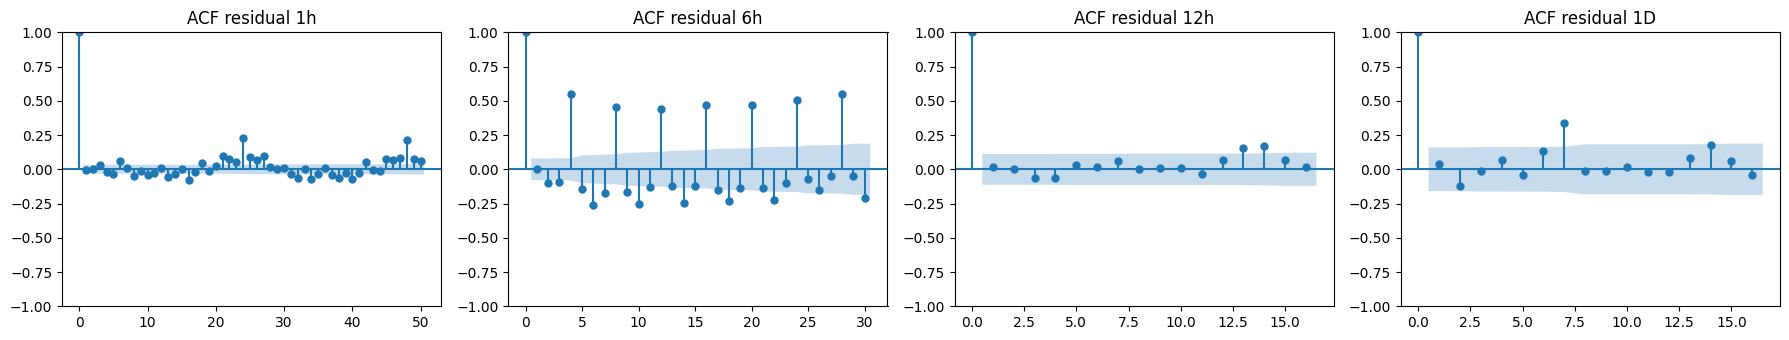

In [31]:
# ===== Diagnostik ARIMA: Ljung-Box pada residual =====
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

TRAIN_END = '2026-08-31'
LB_LAGS = {'1h': [24, 48], '6h': [4, 28], '12h': [4, 14], '1D': [7, 14]}

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for i, fq in enumerate(['1h', '6h', '12h', '1D']):
    y = AGGS[fq].loc[:TRAIN_END, 'net'].dropna()   # ganti 'net' kalau nama kolomnya beda

    # pilih p, q dengan BIC (sama seperti di model utama)
    best = None
    for p in range(3):
        for q in range(3):
            try:
                r = ARIMA(y, order=(p, 0, q), trend='c').fit()
                if best is None or r.bic < best[0]:
                    best = (r.bic, p, q, r)
            except Exception:
                pass
    _, p, q, result = best

    residuals = result.resid
    lb = acorr_ljungbox(residuals, lags=LB_LAGS[fq], model_df=p + q, return_df=True)

    print(f"=== {fq}: ARIMA({p},0,{q}) ===")
    for lag in lb.index:
        pval = lb.loc[lag, 'lb_pvalue']
        status = 'White noise' if pval > 0.05 else 'Autocorrelation detected'
        print(f"  Lag {lag}: p-value = {pval:.4f} -> {status}")

    plot_acf(residuals, lags=max(LB_LAGS[fq]) + 2, ax=axes[i], title=f'ACF residual {fq}')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/arima_residual_acf.png', dpi=150)
plt.show()

In [32]:
# IMPORT AND ARIMA ORDER SELECTION
# The differencing order d is fixed at 0, because the ADF test showed that net
# sentiment is stationary at every bin size. BIC only chooses p and q.
# (BIC cannot compare models with different d: a differenced model is fitted on
#  different data, so its BIC is not comparable.)
from statsmodels.tsa.arima.model import ARIMA
import warnings

ARIMA_TREND = 'n'      # include a constant = the long-run mean sentiment

# Candidate orders: p = 0..2, q = 0..2, d = 0  (8 models; (0,0,0) excluded)
ARIMA_ORDERS = [(p, 1, q) for p in range(3) for q in range(3) if (p, q) != (0, 0)]


def select_arima_order(y_train):

    best_bic = np.inf
    best_order = None

    for order in ARIMA_ORDERS:

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    y_train,
                    order=order,
                    trend=ARIMA_TREND
                ).fit()

            if np.isfinite(model.bic) and model.bic < best_bic:

                best_bic = model.bic
                best_order = order

        except Exception:
            continue

    return best_order, best_bic

In [33]:
# TRAIN AND FORECAST ARIMA

def run_arima(name):

    rows = []
    ARIMA_SELECTED = {}

    for fq, D in DATA.items():

        y = D['y']
        T = D['T']
        max_steps = max(D['steps'])

        for fold_id, (fs, test_orig, train_end) in enumerate(D['folds']):

            # Initial training data
            y_train = y[:train_end]

            if len(y_train) < 30:
                continue

            if not np.isfinite(y_train).all():
                continue

            # Select ARIMA order (p, 0, q) using training data only
            order, bic = select_arima_order(y_train)

            if order is None:
                print(f'ARIMA {fq}, fold {fold_id}: no valid model')
                continue

            ARIMA_SELECTED[(fq, fold_id)] = {
                'order': order,
                'bic': bic
            }

            print(
                f'ARIMA {fq}, fold {fold_id}: '
                f'order={order}, BIC={bic:.2f}'
            )

            # Fit the selected ARIMA model
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    y_train,
                    order=order,
                    trend=ARIMA_TREND          # <-- changed
                ).fit()

            last_end = train_end

            # Forecast from each test origin
            for origin in test_orig:

                # Add newly observed values without refitting parameters
                new_obs = y[last_end:origin + 1]

                if len(new_obs) > 0:

                    if not np.isfinite(new_obs).all():
                        continue

                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")

                        model = model.append(
                            new_obs,
                            refit=False
                        )

                    last_end = origin + 1

                # Generate multi-step forecast
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    forecast = np.asarray(
                        model.forecast(steps=max_steps),
                        dtype=float
                    )

                # Store predictions
                for s in D['steps']:

                    if origin + s >= T:
                        continue

                    y_true = y[origin + s]
                    y_pred = forecast[s - 1]

                    if not np.isfinite(y_true) or not np.isfinite(y_pred):
                        continue

                    rows.append(
                        to_frame(
                            name,
                            fq,
                            s,
                            np.array([origin]),
                            np.array([y_true]),
                            np.array([y_pred])
                        )
                    )

    global ARIMA_SELECTED_MODELS
    ARIMA_SELECTED_MODELS = ARIMA_SELECTED

    if not rows:
        raise ValueError("No valid ARIMA forecasts were generated.")

    return pd.concat(rows, ignore_index=True)

In [34]:
PRED['arima'] = run_arima('arima')

show('arima')

ARIMA 1h, fold 0: order=(2, 1, 1), BIC=-611.01
ARIMA 1h, fold 1: order=(2, 1, 2), BIC=-656.84
ARIMA 1h, fold 2: order=(2, 1, 2), BIC=-690.96
ARIMA 1h, fold 3: order=(2, 1, 2), BIC=-712.95
ARIMA 1h, fold 4: order=(2, 1, 2), BIC=-717.81
ARIMA 1h, fold 5: order=(2, 1, 1), BIC=-721.73
ARIMA 1h, fold 6: order=(2, 1, 2), BIC=-742.94
ARIMA 1h, fold 7: order=(2, 1, 2), BIC=-772.18
ARIMA 1h, fold 8: order=(2, 1, 2), BIC=-799.28
ARIMA 1h, fold 9: order=(2, 1, 1), BIC=-777.81
ARIMA 6h, fold 0: order=(2, 1, 2), BIC=-245.21
ARIMA 6h, fold 1: order=(2, 1, 2), BIC=-261.63
ARIMA 6h, fold 2: order=(2, 1, 2), BIC=-262.50
ARIMA 6h, fold 3: order=(2, 1, 2), BIC=-266.93
ARIMA 6h, fold 4: order=(2, 1, 2), BIC=-280.26
ARIMA 6h, fold 5: order=(2, 1, 2), BIC=-289.15
ARIMA 6h, fold 6: order=(2, 1, 2), BIC=-301.86
ARIMA 6h, fold 7: order=(2, 1, 2), BIC=-310.14
ARIMA 6h, fold 8: order=(2, 1, 2), BIC=-316.94
ARIMA 6h, fold 9: order=(2, 1, 2), BIC=-329.35
ARIMA 12h, fold 0: order=(2, 1, 2), BIC=-179.67
ARIMA 12h, f

,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,arima,719,0.167026,0.184854,0.214002,0.096442
1,1h,6,arima,714,0.214263,0.261927,0.268839,0.181976
2,1h,12,arima,708,0.229230,0.304177,0.286276,0.246393
3,1h,24,arima,696,0.232530,0.254497,0.288493,0.086313
4,1h,72,arima,648,0.243788,0.275759,0.300269,0.115941
5,1h,168,arima,552,0.244220,0.288003,0.295537,0.152024
6,6h,6,arima,119,0.133696,0.172057,0.167420,0.222957
7,6h,12,arima,118,0.166009,0.222374,0.206511,0.253470
8,6h,24,arima,116,0.188560,0.188621,0.234654,0.000326
9,6h,72,arima,108,0.213729,0.213986,0.277810,0.001204


## 9. Compare all models + save

Skill vs "no change" (above 0 = better):


model           xgboost  lightgbm  arima  random_forest
freq horizon_h                                         
1h   1            0.132     0.135  0.096          0.127
     6            0.273     0.276  0.182          0.269
     12           0.310     0.312  0.246          0.311
     24           0.169     0.158  0.086          0.174
     72           0.148     0.146  0.116          0.137
     168          0.176     0.170  0.152          0.168
6h   6            0.277     0.270  0.223          0.295
     12           0.289     0.267  0.253          0.287
     24           0.066     0.055  0.000          0.134
     72           0.091     0.068  0.001          0.106
     168          0.165     0.153 -0.002          0.151
12h  12           0.285     0.291  0.306          0.296
     24           0.114     0.128  0.153          0.111
     72           0.020     0.054  0.188          0.092
     168          0.178     0.147  0.223          0.148
1D   24           0.091     0.160  0.210          0.076
     72          -0.033    -0.047  0.178          0.053
     168          0.053     0.018  0.270          0.101

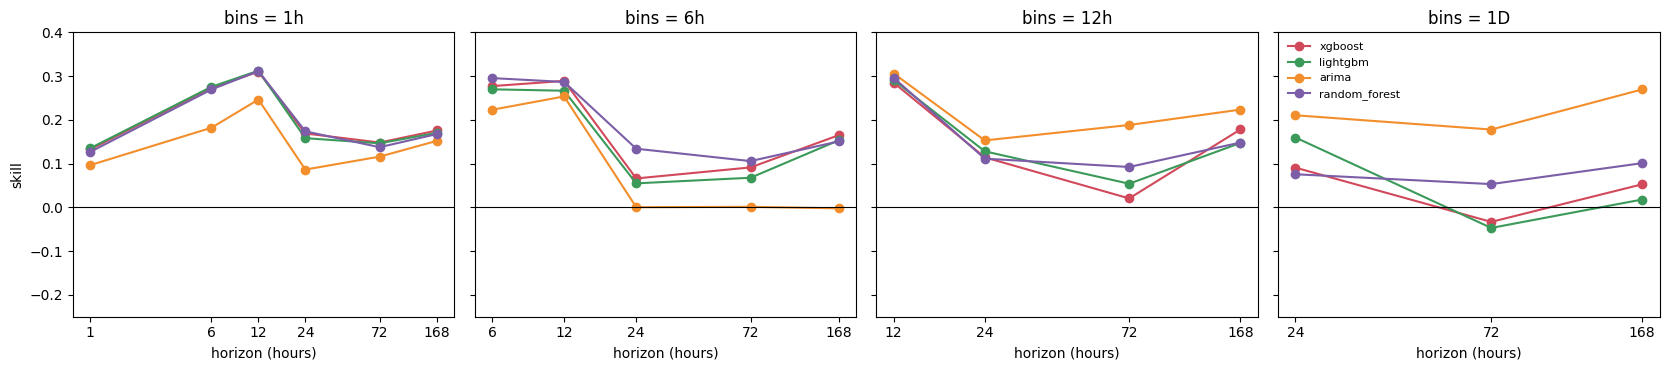

In [35]:
models = [m for m in ('var', 'xgboost', 'lightgbm', 'arima', 'random_forest') if m in PRED]
SCORES = pd.concat([score(m) for m in models], ignore_index=True)
SCORES.to_csv(f'{OUT_DIR}/scores.csv', index=False)
pd.concat(PRED.values(), ignore_index=True).drop(columns='origin').to_csv(
    f'{OUT_DIR}/predictions.csv', index=False)

print('Skill vs "no change" (above 0 = better):')
display(SCORES.pivot_table(index=['freq', 'horizon_h'], columns='model', values='skill',
                           sort=False)[models].round(3))

colors = {'var': '#2a6fbb', 'random_forest':'#7b5ea7', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a', 'arima': '#f28e2b'}
fig, axes = plt.subplots(1, len(DATA), figsize=(4.2 * len(DATA), 3.8), sharey=True, squeeze=False)
for ax, fq in zip(axes[0], DATA):
    g = SCORES[SCORES.freq == fq]
    for m in models:
        gm = g[g.model == m].sort_values('horizon_h')
        ax.plot(gm.horizon_h, gm.skill, marker='o', label=m, color=colors[m])
    hs = sorted(g.horizon_h.unique())
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_xticks(hs); ax.set_xticklabels(hs); ax.minorticks_off()
    ax.set_title(f'bins = {fq}'); ax.set_xlabel('horizon (hours)')
axes[0][0].set_ylabel('skill')
Y_LIM = (-0.25, 0.40)          # same limits in both notebooks (before and after exogenous)
axes[0][0].set_ylim(*Y_LIM)
axes[0][-1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/skill_by_horizon.png', dpi=140); plt.show()

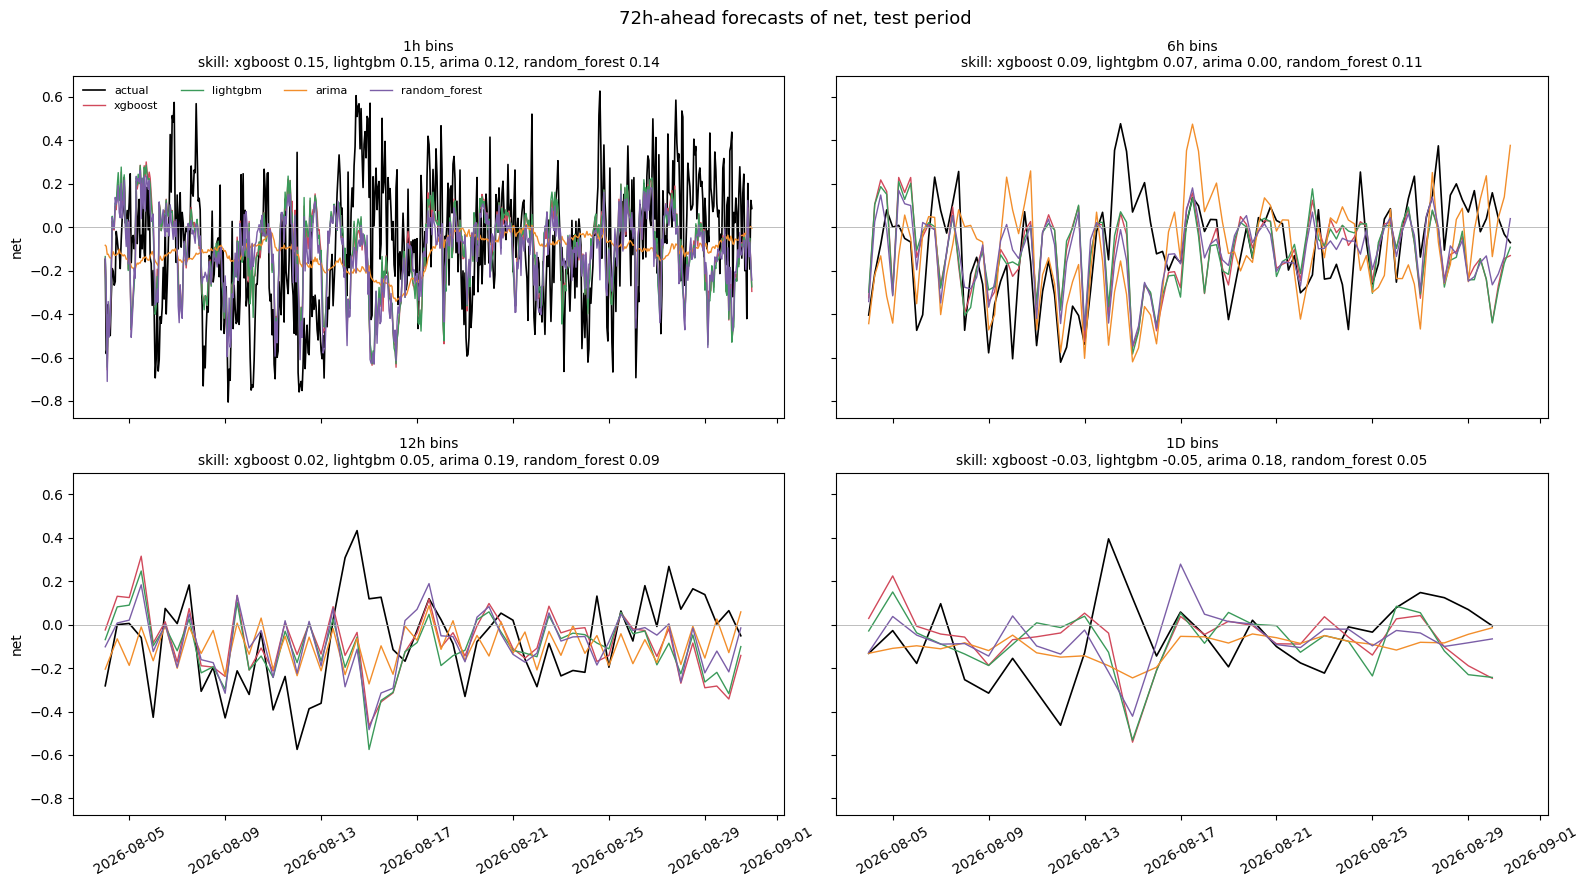

In [36]:
# 24h-ahead forecasts: the four bin sizes in a 2x2 grid
# top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
h = 72
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    if ref.empty:
        ax.set_title(f'{fq} bins: no {h}h horizon'); continue
    ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1.2, label='actual')
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
        ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
    ax.axhline(0, color='0.7', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @h').set_index('model').skill
    ax.set_title(f'{fq} bins\nskill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
for ax in axes[1]:
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=4, fontsize=8, loc='upper left')
fig.suptitle(f'{h}h-ahead forecasts of {TARGET}, test period', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_all_bins.png', dpi=140, bbox_inches='tight'); plt.show()

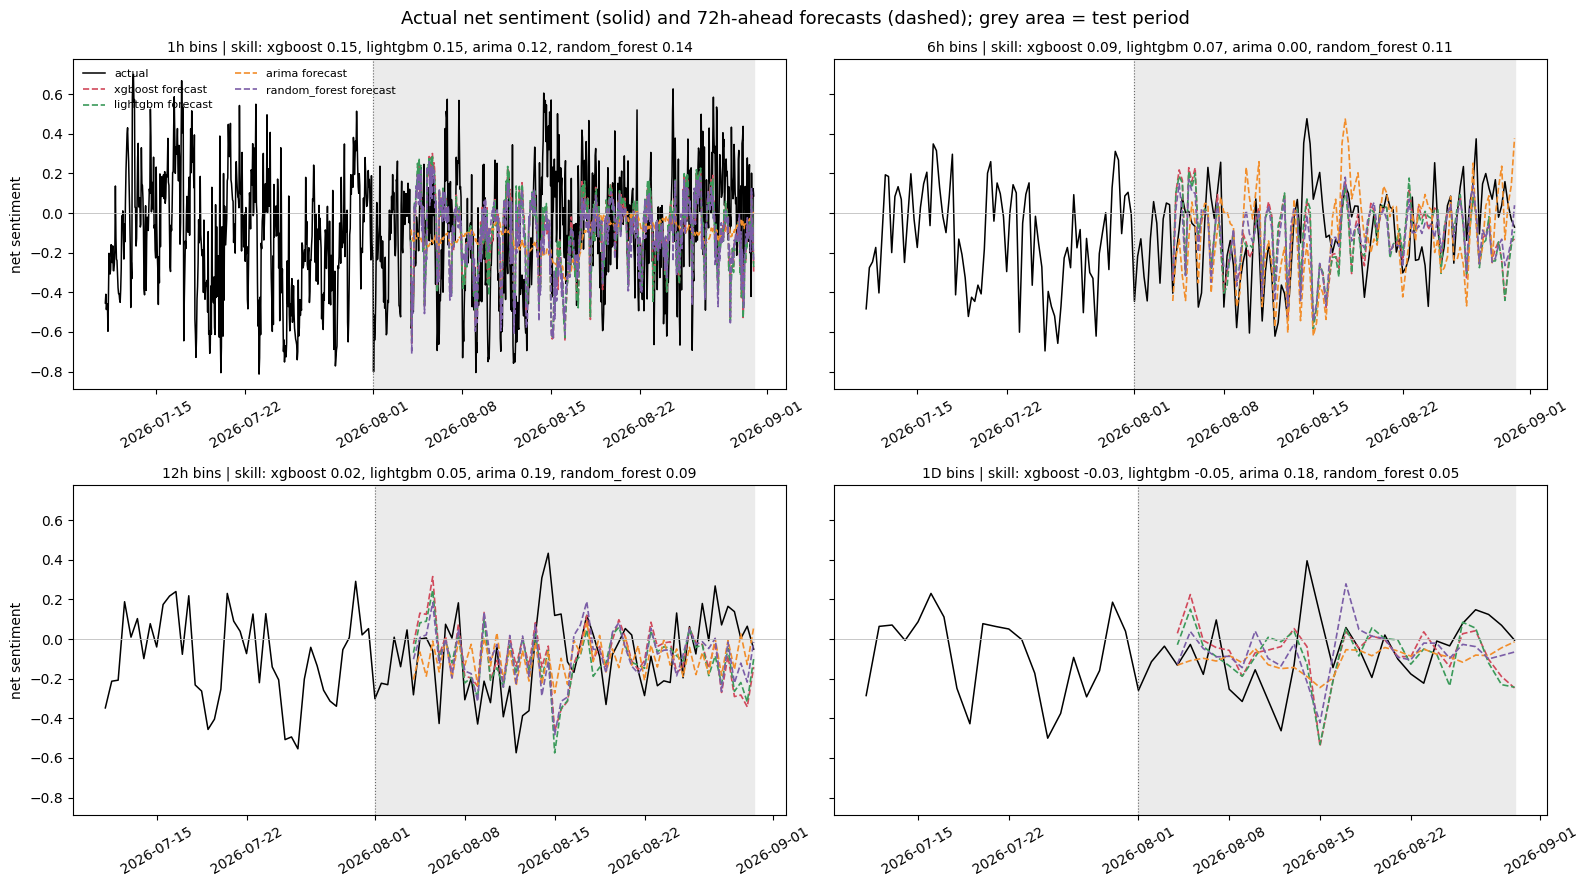

In [37]:
# ===== Forecast vs actual track, 2x2 grid =====
# Solid line   = actual net sentiment (part of the training period + the whole test period)
# Dashed lines = forecasts of each model, placed at the time they forecast (forecast time + horizon)
# Top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
H_PLOT      = 72     # horizon to show (hours): 24, 72 or 168 exist for every bin size
DAYS_BEFORE = 21     # how many days of actual data before the test period to show

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    D = DATA[fq]
    # --- actual track (solid)
    start = TEST_START_TS - pd.Timedelta(days=DAYS_BEFORE)
    actual = pd.Series(D['y'], index=D['times'])
    actual = actual[actual.index >= start]
    ax.plot(actual.index, actual.values, color='k', lw=1.1, label='actual')
    # --- forecasts (dashed)
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @H_PLOT').sort_values('origin_time')
        if g.empty:
            continue
        ax.plot(g.origin_time + pd.Timedelta(hours=H_PLOT), g.y_pred,
                ls='--', lw=1.2, color=colors[m], label=f'{m} forecast')
    # --- mark the test period
    ax.axvspan(TEST_START_TS, actual.index[-1], color='0.92', zorder=0)
    ax.axvline(TEST_START_TS, color='0.4', lw=0.8, ls=':')
    ax.axhline(0, color='0.75', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @H_PLOT').set_index('model').skill
    ax.set_title(f'{fq} bins | skill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes[:, 0]:
    ax.set_ylabel(f'{TARGET} sentiment')
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
fig.suptitle(f'Actual net sentiment (solid) and {H_PLOT}h-ahead forecasts (dashed); '
             f'grey area = test period', fontsize=13)
fig.tight_layout()
fig.savefig(f'{OUT_DIR}/forecast_track_{H_PLOT}h.png', dpi=140, bbox_inches='tight')
plt.show()

In [38]:
# ===== Extra evaluation metrics for =====
#  MAE        average size of the error (same unit as the target)
#  RMSE       like MAE but punishes big misses more
#  bias       average error; > 0 = model forecasts too high on average
#  R2         1 - SSE/SST on the test period (1 = perfect, 0 = no better than the test mean,
#             can be negative)
#  corr       correlation between forecast and actual (pattern match, ignores level)
#  dir_acc    share of forecasts that get the DIRECTION of change right (up vs down)
#  skill      1 - MAE / MAE("no change")
rows = []
pers = PRED['persistence'][['freq', 'horizon_h', 'origin', 'y_pred']].rename(columns={'y_pred': 'y_now'})
for m in models:
    P = PRED[m].merge(pers, on=['freq', 'horizon_h', 'origin'])
    for (fq, h), g in P.groupby(['freq', 'horizon_h'], sort=False):
        e = g.y_pred - g.y_true
        sst = ((g.y_true - g.y_true.mean()) ** 2).sum()
        moved = (g.y_true - g.y_now) != 0
        rows.append(dict(
            freq=fq, horizon_h=h, model=m,
            MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), bias=e.mean(),
            R2=1 - (e ** 2).sum() / sst,
            corr=np.corrcoef(g.y_pred, g.y_true)[0, 1],
            dir_acc=(np.sign(g.y_pred - g.y_now) == np.sign(g.y_true - g.y_now))[moved].mean()))
METRICS = pd.DataFrame(rows).merge(SCORES[['freq', 'horizon_h', 'model', 'skill']],
                                   on=['freq', 'horizon_h', 'model'])
METRICS.to_csv(f'{OUT_DIR}/metrics.csv', index=False)
for col in ('MAE', 'RMSE', 'R2', 'dir_acc'):
    print(f'\n{col}')
    display(METRICS.pivot_table(index=['freq', 'horizon_h'], columns='model', values=col,
                                sort=False)[models].round(3))
print('\nAll metrics saved to', f'{OUT_DIR}/metrics.csv')


MAE


model           xgboost  lightgbm  arima  random_forest
freq horizon_h                                         
1h   1            0.160     0.160  0.167          0.161
     6            0.190     0.190  0.214          0.191
     12           0.210     0.209  0.229          0.209
     24           0.212     0.214  0.233          0.210
     72           0.235     0.235  0.244          0.238
     168          0.237     0.239  0.244          0.240
6h   6            0.124     0.126  0.134          0.121
     12           0.158     0.163  0.166          0.159
     24           0.176     0.178  0.189          0.163
     72           0.194     0.200  0.214          0.191
     168          0.191     0.193  0.229          0.194
12h  12           0.129     0.128  0.125          0.127
     24           0.155     0.153  0.148          0.155
     72           0.199     0.192  0.165          0.184
     168          0.179     0.186  0.169          0.185
1D   24           0.145     0.134  0.126          0.147
     72           0.178     0.181  0.142          0.163
     168          0.196     0.204  0.151          0.186


RMSE


model           xgboost  lightgbm  arima  random_forest
freq horizon_h                                         
1h   1            0.207     0.207  0.214          0.208
     6            0.239     0.238  0.269          0.240
     12           0.263     0.263  0.286          0.262
     24           0.267     0.270  0.288          0.265
     72           0.293     0.293  0.300          0.295
     168          0.302     0.305  0.296          0.303
6h   6            0.158     0.159  0.167          0.153
     12           0.196     0.201  0.207          0.199
     24           0.218     0.220  0.235          0.206
     72           0.244     0.249  0.278          0.240
     168          0.237     0.243  0.276          0.237
12h  12           0.168     0.168  0.155          0.159
     24           0.202     0.203  0.189          0.196
     72           0.245     0.241  0.198          0.234
     168          0.232     0.236  0.201          0.225
1D   24           0.187     0.177  0.163          0.181
     72           0.231     0.238  0.189          0.216
     168          0.256     0.252  0.186          0.222


R2


model           xgboost  lightgbm  arima  random_forest
freq horizon_h                                         
1h   1            0.479     0.480  0.445          0.474
     6            0.300     0.300  0.111          0.290
     12           0.156     0.151 -0.003          0.157
     24           0.132     0.111 -0.012          0.148
     72          -0.018    -0.024 -0.072         -0.035
     168         -0.055    -0.075 -0.008         -0.063
6h   6            0.495     0.486  0.432          0.528
     12           0.229     0.184  0.140          0.201
     24           0.052     0.029 -0.101          0.155
     72          -0.160    -0.208 -0.505         -0.120
     168         -0.070    -0.126 -0.451         -0.068
12h  12           0.294     0.292  0.401          0.367
     24          -0.015    -0.021  0.116          0.042
     72          -0.423    -0.374  0.074         -0.291
     168         -0.235    -0.275  0.075         -0.160
1D   24          -0.211    -0.084  0.078         -0.137
     72          -0.726    -0.845 -0.163         -0.521
     168         -0.922    -0.852 -0.012         -0.438


dir_acc


model           xgboost  lightgbm  arima  random_forest
freq horizon_h                                         
1h   1            0.668     0.668  0.654          0.663
     6            0.766     0.770  0.682          0.770
     12           0.780     0.777  0.750          0.770
     24           0.705     0.701  0.680          0.710
     72           0.701     0.698  0.705          0.698
     168          0.707     0.707  0.701          0.688
6h   6            0.798     0.815  0.790          0.790
     12           0.737     0.729  0.729          0.746
     24           0.647     0.655  0.543          0.690
     72           0.741     0.722  0.556          0.741
     168          0.652     0.674  0.446          0.663
12h  12           0.763     0.814  0.797          0.797
     24           0.707     0.724  0.690          0.707
     72           0.685     0.685  0.704          0.685
     168          0.674     0.652  0.739          0.630
1D   24           0.759     0.690  0.793          0.655
     72           0.741     0.741  0.778          0.741
     168          0.565     0.609  0.696          0.739


All metrics saved to results_withengagement1/metrics.csv


In [39]:
# ===== ARIMA: training vs test error =====
# Same idea as the ML check: forecast h steps ahead from many origins and compare with the actual.
#   training error: origins inside the training period
#   test error    : origins inside the test period
# Parameters are estimated once on the training period (no refit), with the SAME candidate
# orders and trend as the main ARIMA cell, so the result matches the model that was evaluated.
import numpy as np, pandas as pd, warnings
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings('ignore')

BIN_H  = {'1h': 1, '6h': 6, '12h': 12, '1D': 24}
ORDERS = ARIMA_ORDERS if 'ARIMA_ORDERS' in globals() else [(p, 0, q) for p in range(3) for q in range(3)]
TREND  = ARIMA_TREND  if 'ARIMA_TREND'  in globals() else 'c'

rows, ARIMA_TT_ORDER = [], {}
for fq in ['1h', '6h', '12h', '1D']:
    s    = AGGS[fq][TARGET].dropna()
    y_tr = s[s.index <  TEST_START_TS].to_numpy()
    y_te = s[s.index >= TEST_START_TS].to_numpy()

    # choose (p, d, q) by BIC on the training period
    best = None
    for order in ORDERS:
        try:
            r = ARIMA(y_tr, order=order, trend=TREND).fit()
            if best is None or r.bic < best[0]:
                best = (r.bic, order, r)
        except Exception:
            pass
    _, order, res = best
    ARIMA_TT_ORDER[fq] = order

    res_all = res.append(y_te, refit=False)     # add the test data, keep the parameters
    y_all   = np.concatenate([y_tr, y_te])
    n_tr    = len(y_tr)

    bh        = BIN_H[fq]
    hs        = [h for h in HORIZONS_H if h >= bh and h % bh == 0]
    max_steps = max(hs) // bh
    stride    = 7 if bh == 1 else max(1, 24 // bh)   # 1h: every 7 h, so origins rotate over all hours
    warm      = int(0.2 * n_tr)                      # skip the start of the series (model warm-up)

    for part, origins in [('train', range(warm, n_tr - max_steps, stride)),
                          ('test',  range(n_tr - 1, len(y_all) - 1, stride))]:
        errs = {h: [] for h in hs}
        for o in origins:
            end = min(o + max_steps, len(y_all) - 1)
            f = res_all.predict(start=o + 1, end=end, dynamic=True)   # uses information up to o only
            for h in hs:
                k = h // bh
                if o + k <= end:
                    errs[h].append(abs(f[k - 1] - y_all[o + k]))
        for h in hs:
            if errs[h]:
                rows.append(dict(freq=fq, horizon_h=h, part=part, mae=np.mean(errs[h])))
    print(f'{fq}: ARIMA{order} done')

tt_arima = pd.DataFrame(rows)
tab = tt_arima.pivot_table(index=['freq', 'horizon_h'], columns='part', values='mae', sort=False)
tab['ratio'] = tab['test'] / tab['train']
display(tab.round(3))

1h: ARIMA(2, 1, 1) done
6h: ARIMA(2, 1, 2) done
12h: ARIMA(2, 1, 2) done
1D: ARIMA(0, 1, 2) done


part            train   test  ratio
freq horizon_h                     
1h   1          0.171  0.175  1.023
     6          0.236  0.227  0.960
     12         0.266  0.237  0.890
     24         0.256  0.202  0.789
     72         0.267  0.221  0.828
     168        0.263  0.262  0.999
6h   6          0.152  0.136  0.893
     12         0.179  0.136  0.761
     24         0.170  0.200  1.178
     72         0.222  0.232  1.042
     168        0.216  0.202  0.936
12h  12         0.121  0.133  1.095
     24         0.155  0.146  0.947
     72         0.196  0.143  0.727
     168        0.206  0.151  0.735
1D   24         0.143  0.127  0.892
     72         0.172  0.138  0.806
     168        0.185  0.152  0.825

In [44]:
# ===== TRAINING vs TEST ERROR (overfitting check) =====
# Training error: each model is fitted on the data before the first test fold
#                 and then predicts that SAME training data.
# Test error    : the walk-forward errors on the test period already computed (score()).
# A test error much larger than the training error = the model memorised the training data.
# ARIMA is handled in its own cell (multi-step forecasts from training origins).

MAKERS = {'xgboost': globals().get('make_xgb'),
          'lightgbm': globals().get('make_lgb'),
          'random_forest': globals().get('make_rf')}
TT_MODELS = [m for m, f in MAKERS.items() if f is not None and m in PRED]
print('Models included:', TT_MODELS)

TT_ROWS = []
for fq, D in DATA.items():
    X, y, w, T = D['X'], D['y'], D['w'], D['T']
    _, _, train_end = D['folds'][0]                 # cutoff = start of the test period

    # ---- refit on the training period, predict the training period
    for name in TT_MODELS:
        for s in D['steps']:
            tr = np.where(D['valid'] & (np.arange(T) + s < train_end))[0]
            if len(tr) < 50:
                continue
            m = MAKERS[name]()
            m.fit(X[tr], y[tr + s] - y[tr], sample_weight=w[tr + s])
            pred = y[tr] + m.predict(X[tr])
            TT_ROWS.append(dict(freq=fq, horizon_h=s * D['hours'], model=name,
                                MAE_train=np.mean(np.abs(pred - y[tr + s])),
                                MAE_pers_train=np.mean(np.abs(y[tr] - y[tr + s]))))

TT = pd.DataFrame(TT_ROWS)
TT['skill_train'] = 1 - TT.MAE_train / TT.MAE_pers_train

test_scores = pd.concat([score(m) for m in TT_MODELS])
TT = TT.merge(test_scores[['freq', 'horizon_h', 'model', 'MAE', 'skill']]
                .rename(columns={'MAE': 'MAE_test', 'skill': 'skill_test'}),
              on=['freq', 'horizon_h', 'model'])
TT['MAE_ratio'] = TT.MAE_test / TT.MAE_train      # > 1 = larger error on unseen data
TT['skill_gap'] = TT.skill_train - TT.skill_test  # > 0 = model does better on data it has seen
TT.to_csv(f'{OUT_DIR}/train_vs_test_error.csv', index=False)

print('\nMAE training vs test, per bin size (mean over horizons)')
display(TT.pivot_table(index='freq', columns='model', values=['MAE_train', 'MAE_test', 'MAE_ratio'],
                       sort=False).reindex(['1h', '6h', '12h', '1D']).round(3))
print('\nSkill training vs test, per bin size (mean over horizons)')
display(TT.pivot_table(index='freq', columns='model', values=['skill_train', 'skill_test', 'skill_gap'],
                       sort=False).reindex(['1h', '6h', '12h', '1D']).round(3))

Models included: ['xgboost', 'lightgbm', 'random_forest']

MAE training vs test, per bin size (mean over horizons)


MAE_train                        MAE_test                         \
model   xgboost lightgbm random_forest  xgboost lightgbm random_forest   
freq                                                                     
1h        0.150    0.145         0.164    0.207    0.208         0.208   
6h        0.078    0.079         0.135    0.169    0.172         0.166   
12h       0.057    0.090         0.138    0.165    0.164         0.163   
1D        0.041    0.107         0.148    0.173    0.173         0.166   

      MAE_ratio                         
model   xgboost lightgbm random_forest  
freq                                    
1h        1.374    1.432         1.268  
6h        2.166    2.165         1.222  
12h       2.897    1.822         1.178  
1D        4.257    1.604         1.127


Skill training vs test, per bin size (mean over horizons)


skill_train                        skill_test                         \
model     xgboost lightgbm random_forest    xgboost lightgbm random_forest   
freq                                                                         
1h          0.420    0.442         0.370      0.201    0.200         0.198   
6h          0.645    0.639         0.382      0.178    0.162         0.194   
12h         0.707    0.540         0.294      0.149    0.155         0.162   
1D          0.776    0.417         0.202      0.037    0.043         0.077   

      skill_gap                         
model   xgboost lightgbm random_forest  
freq                                    
1h        0.218    0.242         0.172  
6h        0.467    0.476         0.188  
12h       0.557    0.385         0.132  
1D        0.739    0.374         0.125


MAE_train (mean over horizons)


model,arima,xgboost,lightgbm,random_forest
freq,,,,
1h,0.243,0.150,0.145,0.164
6h,0.188,0.078,0.079,0.135
12h,0.169,0.057,0.090,0.138
1D,0.166,0.041,0.107,0.148



MAE_test (mean over horizons)


model,arima,xgboost,lightgbm,random_forest
freq,,,,
1h,0.222,0.207,0.208,0.208
6h,0.186,0.169,0.172,0.166
12h,0.152,0.165,0.164,0.163
1D,0.140,0.173,0.173,0.166



MAE_ratio (mean over horizons)


model,arima,xgboost,lightgbm,random_forest
freq,,,,
1h,0.913,1.379,1.437,1.270
6h,0.991,2.173,2.176,1.226
12h,0.895,2.893,1.831,1.181
1D,0.838,4.225,1.615,1.121


ARIMA test error = walk-forward


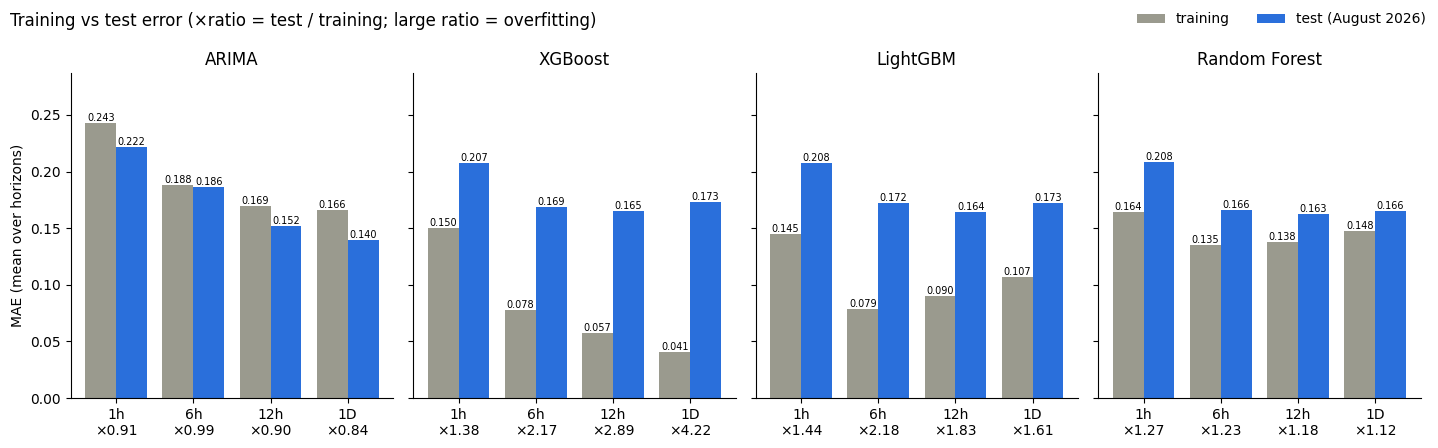

In [45]:
# ===== TRAINING vs TEST ERROR: all models in one chart =====
# Run AFTER the ML training-vs-test cell (makes TT) and the ARIMA cell (makes tt_arima).
# Training error : ML = refit on the training period and predict it; ARIMA = multi-step forecasts
#                  from origins in the training period (fixed parameters).
# Test error     : the walk-forward error from score() for every model that was run in this notebook.
#                  If ARIMA was not run here, its test error comes from the ARIMA cell instead.

# --- ARIMA rows in the same format as TT -------------------------------------------
ar = (tt_arima.pivot_table(index=['freq', 'horizon_h'], columns='part', values='mae')
              .reset_index()
              .rename(columns={'train': 'MAE_train', 'test': 'MAE_test'}))
ar['model'] = 'arima'
if 'arima' in PRED:
    wf = score('arima')[['freq', 'horizon_h', 'MAE']].rename(columns={'MAE': 'MAE_test'})
    ar = ar.drop(columns='MAE_test').merge(wf, on=['freq', 'horizon_h'])
    arima_note = 'ARIMA test error = walk-forward'
else:
    arima_note = 'ARIMA test error = fixed parameters (ARIMA not run in this notebook)'

COLS   = ['freq', 'horizon_h', 'model', 'MAE_train', 'MAE_test']
ALL_TT = pd.concat([ar[COLS], TT[COLS]], ignore_index=True).dropna()
ALL_TT['MAE_ratio'] = ALL_TT.MAE_test / ALL_TT.MAE_train
ALL_TT.to_csv(f'{OUT_DIR}/train_vs_test_error_all_models.csv', index=False)

ORDER  = [m for m in ['arima', 'var', 'xgboost', 'lightgbm', 'random_forest'] if m in set(ALL_TT.model)]
LABEL  = {'arima': 'ARIMA', 'var': 'VAR', 'xgboost': 'XGBoost', 'lightgbm': 'LightGBM',
          'random_forest': 'Random Forest'}
BINS   = [b for b in ['1h', '6h', '12h', '1D'] if b in set(ALL_TT.freq)]
TEST_LABEL = f'test ({TEST_START_TS:%B %Y})'

# --- tables: mean over horizons ------------------------------------------------------
summ = (ALL_TT.groupby(['freq', 'model'])[['MAE_train', 'MAE_test']].mean()
              .assign(MAE_ratio=lambda d: d.MAE_test / d.MAE_train))
for col in ['MAE_train', 'MAE_test', 'MAE_ratio']:
    print(f'\n{col} (mean over horizons)')
    display(summ[col].unstack('model').reindex(index=BINS, columns=ORDER).round(3))
print(arima_note)

# --- chart: one panel per model ------------------------------------------------------
fig, axes = plt.subplots(1, len(ORDER), figsize=(3.6 * len(ORDER), 4.5), sharey=True)
xx = np.arange(len(BINS))
for ax, mdl in zip(np.atleast_1d(axes), ORDER):
    g = summ.xs(mdl, level='model').reindex(BINS)
    b1 = ax.bar(xx - 0.2, g.MAE_train, 0.4, color='#9a9a8e', label='training')
    b2 = ax.bar(xx + 0.2, g.MAE_test,  0.4, color='#2a6fdb', label=TEST_LABEL)
    ax.bar_label(b1, fmt='%.3f', fontsize=7)
    ax.bar_label(b2, fmt='%.3f', fontsize=7)
    ax.set_xticks(xx, [f'{b}\n×{r:.2f}' for b, r in zip(BINS, g.MAE_ratio)])   # ratio under each bin
    ax.set_title(LABEL[mdl])
    ax.spines[['top', 'right']].set_visible(False)
axes = np.atleast_1d(axes)
axes[0].set_ylabel('MAE (mean over horizons)')
axes[0].set_ylim(0, summ[['MAE_train', 'MAE_test']].max().max() * 1.18)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2, loc='upper right')
fig.suptitle('Training vs test error (×ratio = test / training; large ratio = overfitting)',
             x=0.01, ha='left', fontsize=12)
fig.tight_layout()
fig.savefig(f'{OUT_DIR}/train_vs_test_error_all_models.png', dpi=200, bbox_inches='tight')
plt.show()

Horizon 24h | share_% = share of total importance within one model and bin
Method per model: {'lightgbm': 'mean |SHAP|', 'random_forest': 'mean |SHAP|', 'xgboost': 'mean |SHAP|'} 

Share of importance by feature group (%)


group               net history  post volume  engagement  calendar
freq model                                                        
1h   xgboost               56.3         10.7         7.4      25.7
     lightgbm              56.7         10.4         6.7      26.1
     random_forest         64.0         13.6         6.7      15.6
6h   xgboost               58.3         15.0        10.3      16.3
     lightgbm              57.3         14.9        10.1      17.7
     random_forest         72.4          8.3         7.9      11.5
12h  xgboost               58.9         18.8         9.1      13.2
     lightgbm              56.9         18.4         9.6      15.1
     random_forest         78.5          6.9         5.2       9.4
1D   xgboost               64.7         13.5        10.8      10.9
     lightgbm              60.2         14.8        11.6      13.4
     random_forest         84.8          3.2         1.6      10.4

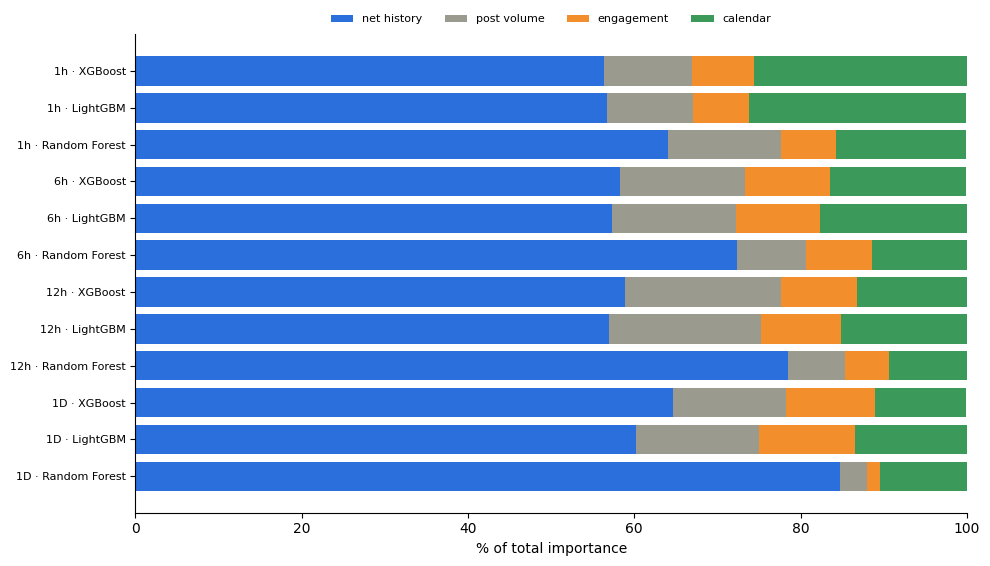

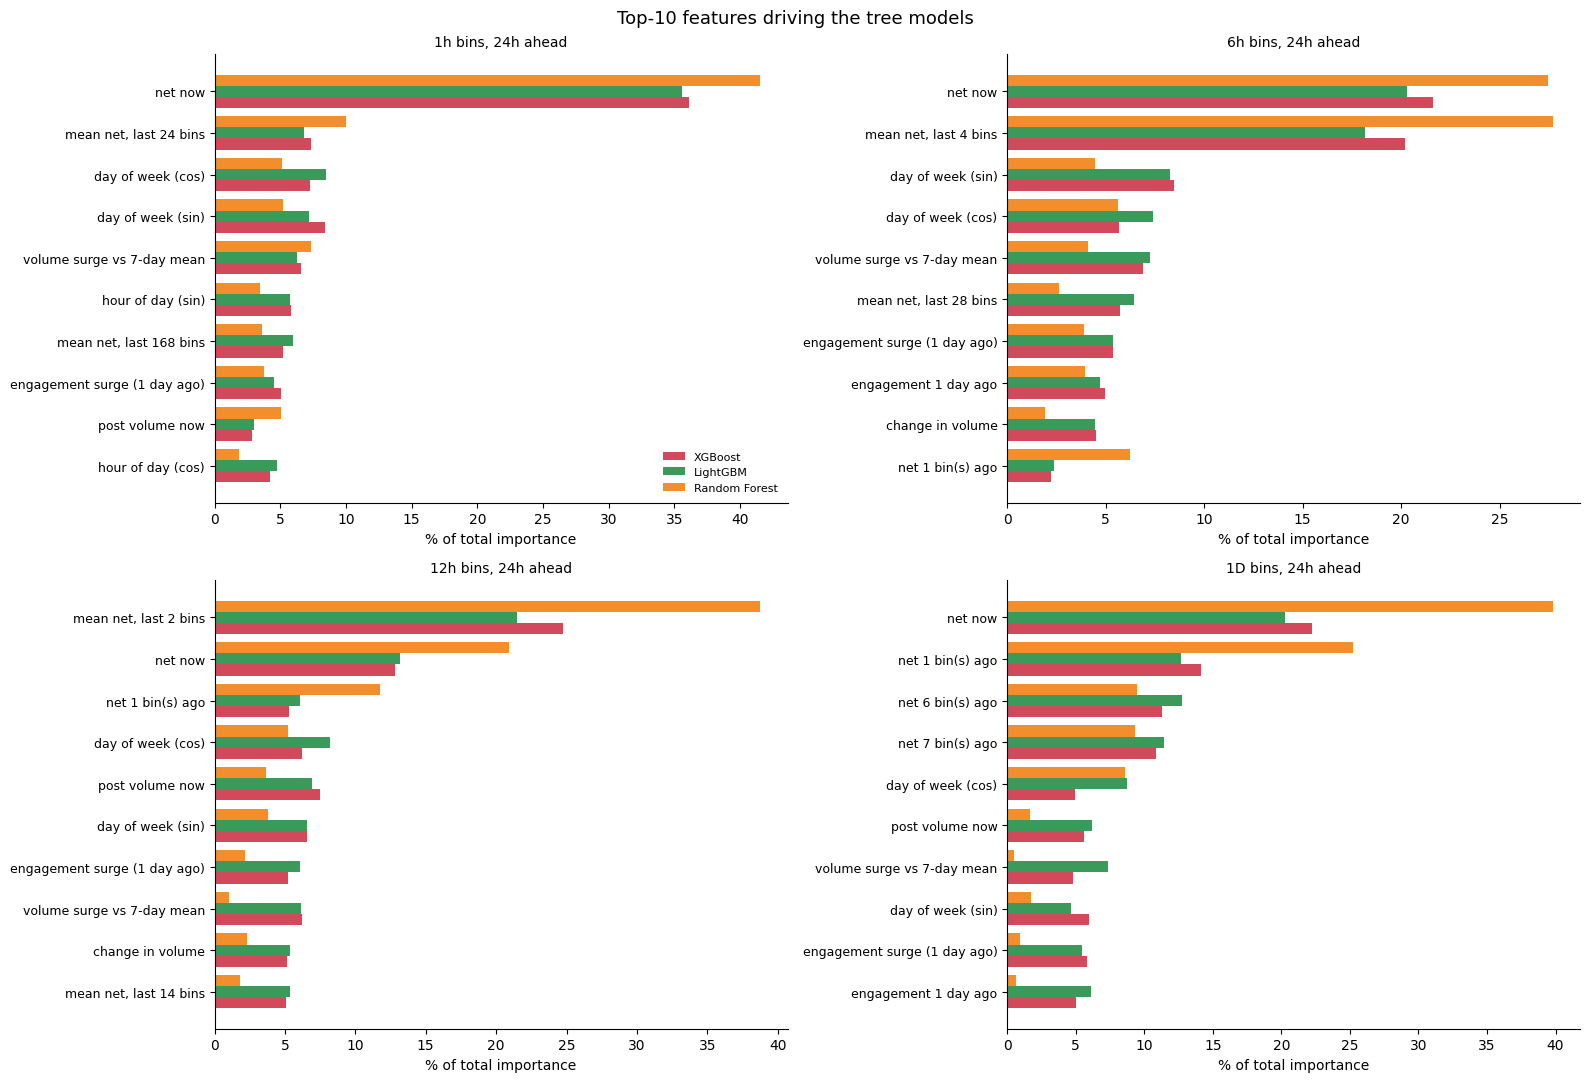

In [46]:
# ===== 13. Which features drive the tree models? (SHAP) =====
# Uses the models from the last test fold and explains their forecasts on the test period.
# XGBoost / LightGBM: SHAP computed by the library itself.
# Random Forest     : SHAP with the shap package (TreeExplainer); if shap is missing,
#                     permutation importance is used instead (printed below).
H_EXPLAIN = 24          # horizon (hours) to explain; must exist for the bin sizes
RF_MAX_ROWS = 500       # Random Forest SHAP is slower: explain at most this many test rows

FEATURE_INFO = {
    'y_lag0': 'net now', 'y_diff1': 'change since last bin', 'y_dev_week': 'net vs its 7-day mean',
    'y_std_recent': 'volatility over last day',
    'logn': 'post volume now', 'logn_surge': 'volume surge vs 7-day mean',
    'logn_diff1': 'change in volume', 'is_empty': 'empty bin flag',
    'log_eng_lag1d': 'engagement 1 day ago', 'log_eng_surge1d': 'engagement surge (1 day ago)',
    'share_neu': 'neutral share', 'share_pos': 'positive share', 'share_neg': 'negative share',
    'hour_sin': 'hour of day (sin)', 'hour_cos': 'hour of day (cos)',
    'dow_sin': 'day of week (sin)', 'dow_cos': 'day of week (cos)',
    'is_weekend': 'weekend flag', 'is_active_hours': 'active hours flag', 'is_holiday': 'holiday flag'}

def describe(f):
    if f in FEATURE_INFO:      return FEATURE_INFO[f]
    if f.startswith('y_lag'):  return f'net {f[5:]} bin(s) ago'
    if f.startswith('y_mean'): return f'mean net, last {f[6:]} bins'
    if f.startswith('plat_'):  return f'{f[5:]} share of posts'
    return f

def feature_group(f):
    if f.startswith('y_'):                          return 'net history'
    if f.startswith('log_eng'):                     return 'engagement'
    if f.startswith('logn') or f == 'is_empty':     return 'post volume'
    if f.startswith('share'):                       return 'sentiment shares'
    if f.startswith(('hour_', 'dow_')):             return 'calendar'
    if f.startswith(('plat_', 'news')) or f in ('is_weekend', 'is_active_hours', 'is_holiday'):
        return 'exogenous'
    return 'other'

def importance(name, m, X, y_delta):
    """mean |SHAP| per feature; falls back to permutation importance."""
    try:
        if name == 'xgboost':
            c = m.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]
        elif name == 'lightgbm':
            c = np.asarray(m.predict(X, pred_contrib=True))[:, :-1]
        else:
            import shap
            c = shap.TreeExplainer(m).shap_values(X, check_additivity=False)
        return np.abs(np.asarray(c)).mean(0), 'mean |SHAP|'
    except Exception as e:
        from sklearn.inspection import permutation_importance
        r = permutation_importance(m, X, y_delta, n_repeats=5, random_state=0,
                                   scoring='neg_mean_absolute_error')
        return np.clip(r.importances_mean, 0, None), f'permutation ({type(e).__name__})'

STORES = {'xgboost': globals().get('XGB_MODELS'), 'lightgbm': globals().get('LGB_MODELS'),
          'random_forest': globals().get('RF_MODELS')}
STORES = {k: v for k, v in STORES.items() if v}

IMP_ROWS = []
rng = np.random.default_rng(0)
for fq, D in DATA.items():
    s = H_EXPLAIN // D['hours']
    if H_EXPLAIN % D['hours']:
        continue
    idx = np.where((D['times'] >= TEST_START_TS) & D['valid'] & (np.arange(D['T']) + s < D['T']))[0]
    for name, store in STORES.items():
        keys = [k for k in store if k[0] == fq and k[1] == H_EXPLAIN]
        if not keys:
            continue
        m = store[max(keys, key=lambda k: k[2])]                 # model from the last fold
        use = idx
        if name == 'random_forest' and len(idx) > RF_MAX_ROWS:
            use = np.sort(rng.choice(idx, RF_MAX_ROWS, replace=False))
        Xt, yd = D['X'][use], D['y'][use + s] - D['y'][use]
        imp, how = importance(name, m, Xt, yd)
        for f, v in zip(D['feature_names'], imp):
            IMP_ROWS.append(dict(freq=fq, model=name, feature=f, description=describe(f),
                                 group=feature_group(f), importance=v, method=how))

IMP = pd.DataFrame(IMP_ROWS)
IMP['share_%'] = 100 * IMP.importance / IMP.groupby(['freq', 'model']).importance.transform('sum')
IMP.to_csv(f'{OUT_DIR}/feature_importance_trees.csv', index=False)

MODEL_LABEL_IMP = {'xgboost': 'XGBoost', 'lightgbm': 'LightGBM', 'random_forest': 'Random Forest'}
MODEL_COLOR_IMP = {'xgboost': '#d1495b', 'lightgbm': '#3b9a5a', 'random_forest': '#f28e2b'}
models_imp = [m for m in MODEL_LABEL_IMP if m in set(IMP.model)]

print(f'Horizon {H_EXPLAIN}h | share_% = share of total importance within one model and bin')
print('Method per model:', IMP.groupby('model').method.first().to_dict(), '\n')

# --- table: importance by feature group --------------------------------------------
GROUP_ORDER = ['net history', 'post volume', 'engagement', 'sentiment shares',
               'calendar', 'exogenous', 'other']
TREE_GROUP_SHARE = IMP.pivot_table(index=['freq', 'model'], columns='group', values='share_%',
                                   aggfunc='sum', sort=False).round(1)
TREE_GROUP_SHARE = TREE_GROUP_SHARE[[g for g in GROUP_ORDER if g in TREE_GROUP_SHARE.columns]]
print('Share of importance by feature group (%)')
display(TREE_GROUP_SHARE)

# --- chart 1: group shares as stacked bars ------------------------------------------
GROUP_COLOR = {'net history': '#2a6fdb', 'post volume': '#9a9a8e', 'engagement': '#f28e2b',
               'sentiment shares': '#8ab4ec', 'calendar': '#3b9a5a', 'exogenous': '#7b5ea7',
               'other': '#cfcfc6'}
gs = TREE_GROUP_SHARE.fillna(0)
labels = [f'{fq} · {MODEL_LABEL_IMP[m]}' for fq, m in gs.index]
fig, ax = plt.subplots(figsize=(10, 0.38 * len(gs) + 1.2))
left = np.zeros(len(gs))
for g in gs.columns:
    ax.barh(np.arange(len(gs)), gs[g], left=left, color=GROUP_COLOR.get(g, '#cfcfc6'), label=g)
    left += gs[g].to_numpy()
ax.set_yticks(np.arange(len(gs)), labels, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel('% of total importance')
ax.legend(frameon=False, ncol=len(gs.columns), fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0))
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/feature_importance_groups.png', dpi=140, bbox_inches='tight')
plt.show()

# --- chart 2: top-10 features per bin size, the three models side by side -------------
freqs_imp = list(dict.fromkeys(IMP.freq))
bw = 0.8 / len(models_imp)
fig, axes = plt.subplots(2, 2, figsize=(16, 11), squeeze=False)
for ax, fq in zip(axes.ravel(), freqs_imp):
    g = IMP[IMP.freq == fq]
    top = g.groupby('description')['share_%'].mean().nlargest(10).index[::-1]
    yy = np.arange(len(top))
    for j, name in enumerate(models_imp):
        v = g[g.model == name].set_index('description')['share_%'].reindex(top).fillna(0)
        ax.barh(yy + (j - (len(models_imp) - 1) / 2) * bw, v, height=bw,
                color=MODEL_COLOR_IMP[name], label=MODEL_LABEL_IMP[name])
    ax.set_yticks(yy); ax.set_yticklabels(top, fontsize=9)
    ax.set_xlabel('% of total importance'); ax.set_title(f'{fq} bins, {H_EXPLAIN}h ahead', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.ravel()[len(freqs_imp):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Top-10 features driving the tree models', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/feature_importance_trees.png', dpi=140, bbox_inches='tight')
plt.show()

In [47]:
# ===================== CELL A: data for the visuals =====================
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE_DIR = OUT_DIR                        # results of THIS notebook
base = pd.read_csv(f'{BASE_DIR}/scores.csv')

BIN_ORDER   = ['1h', '6h', '12h', '1D']
BIN_LABEL   = {'1h': '1 jam', '6h': '6 jam', '12h': '12 jam', '1D': '1 hari'}
MODEL_ORDER = [m for m in ['arima', 'var', 'xgboost', 'lightgbm', 'random_forest'] if m in set(base.model)]
MODEL_LABEL = {'arima': 'ARIMA', 'var': 'VAR', 'xgboost': 'XGBoost', 'lightgbm': 'LightGBM', 'random_forest':'Random Forest'}
MODEL_COLOR = {'arima': '#2a6fdb', 'var': '#8ab4ec', 'xgboost': '#9a9a8e', 'lightgbm': '#cfcfc6', 'random_forest':'#f28e2b'}

def fmt(v, sign=False):
    s = f'{v:+.3f}' if sign else f'{v:.3f}'
    return s.replace('.', ',').replace('-', '−')

def horizon_group(h):
    return '≤ 12 jam' if h <= 12 else f'{h} jam'
HZ_ORDER = ['≤ 12 jam', '24 jam', '72 jam', '168 jam']

print('Loaded', len(base), 'rows from', f'{BASE_DIR}/scores.csv', '| models:', MODEL_ORDER)

Loaded 72 rows from results_withengagement1/scores.csv | models: ['arima', 'xgboost', 'lightgbm', 'random_forest']


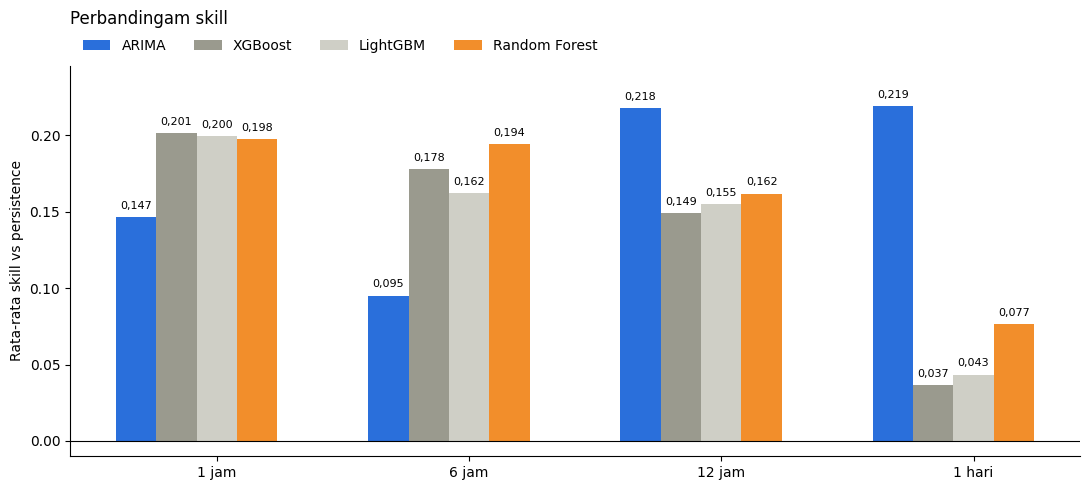

In [48]:
mean_bin = (base.groupby(['freq', 'model']).skill.mean()
                .unstack('model').reindex(BIN_ORDER)[MODEL_ORDER])

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(BIN_ORDER))
w = 0.16
for i, m in enumerate(MODEL_ORDER):
    vals = mean_bin[m].to_numpy()
    bars = ax.bar(x + (i - 2) * w, vals, w, label=MODEL_LABEL[m], color=MODEL_COLOR[m])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, fmt(v), ha='center', va='bottom', fontsize=8)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x, [BIN_LABEL[b] for b in BIN_ORDER])
ax.set_ylabel('Rata-rata skill vs persistence')
ax.set_ylim(min(0, mean_bin.min().min()) - 0.01, mean_bin.max().max() * 1.12)
ax.set_title('Perbandingam skill',
             loc='left', fontsize=12, pad=30)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(f'{BASE_DIR}/chart_skill_per_bin.png', dpi=200, bbox_inches='tight')
plt.show()

In [49]:
import pandas as pd, numpy as np, statsmodels.api as sm

A = pd.read_csv('results_changefeat+exog4/predictions.csv')   # baseline
B = pd.read_csv('results_withengagement1/predictions.csv')    # + engagement
BIN_H = {'1h': 1, '6h': 6, '12h': 12, '1D': 24}

rows = []
for (m, fq, h), a in A.groupby(['model', 'freq', 'horizon_h']):
    if m in ('persistence', 'arima'):
        continue
    b = B[(B.model == m) & (B.freq == fq) & (B.horizon_h == h)]
    d = a.merge(b, on='origin_time', suffixes=('_a', '_b'))
    if len(d) < 10:
        continue
    # selisih error: negatif = engagement lebih baik
    loss = (d.y_pred_b - d.y_true_b).abs() - (d.y_pred_a - d.y_true_a).abs()
    L = max(1, h // BIN_H[fq] - 1)            # koreksi autokorelasi antar prakiraan
    r = sm.OLS(loss.to_numpy(), np.ones(len(loss))).fit(cov_type='HAC', cov_kwds={'maxlags': L})
    rows.append(dict(model=m, freq=fq, horizon_h=h, n=len(d),
                     mean_diff=loss.mean(), p=r.pvalues[0]))

dm = pd.DataFrame(rows)
display(dm.pivot_table(index=['freq', 'horizon_h'], columns='model', values='p', sort=False).round(3))
sig = dm[dm.p < 0.05]
print(f'signifikan (p < 0.05): {len(sig)} dari {len(dm)} | '
      f'engagement lebih baik: {(sig.mean_diff < 0).sum()}, lebih buruk: {(sig.mean_diff > 0).sum()}')

model           lightgbm  random_forest  xgboost
freq horizon_h                                  
12h  12            0.848          0.488    0.884
     24            0.289          0.738    0.195
     72            0.665          0.908    0.860
     168           0.276          0.081    0.065
1D   24            0.445          0.173    0.233
     72            0.538          0.982    0.425
     168           0.746          0.094    0.346
1h   12            0.611          0.441    0.913
     24            0.964          0.493    0.630
     72            0.063          0.705    0.225
     168           0.499          0.482    0.532
     1             0.511          0.845    0.697
     6             0.446          0.071    0.266
6h   12            0.350          0.061    0.881
     24            0.226          0.343    0.277
     72            0.594          0.979    0.887
     168           0.031          0.271    0.424
     6             0.817          0.093    0.672

signifikan (p < 0.05): 1 dari 54 | engagement lebih baik: 1, lebih buruk: 0


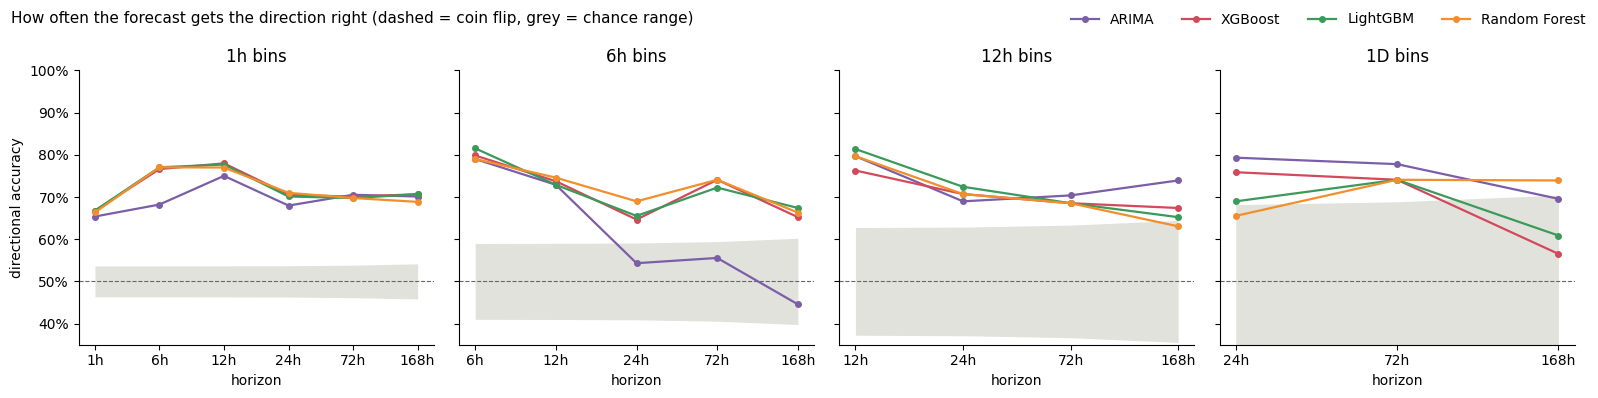

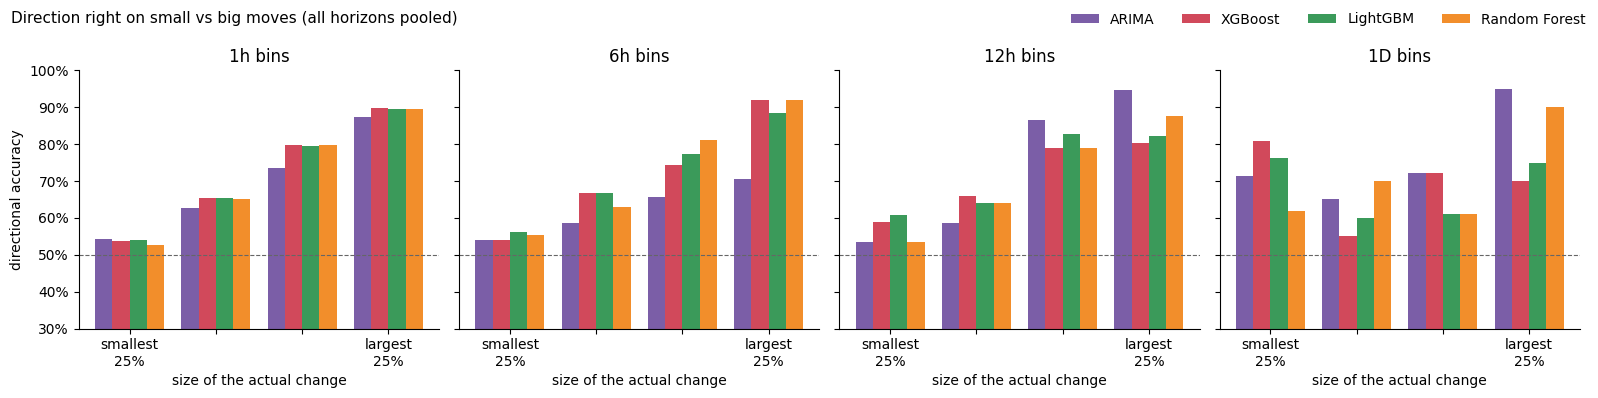

model,arima,xgboost,lightgbm,random_forest
freq,,,,
1h,0.695,0.722,0.721,0.718
6h,0.622,0.718,0.722,0.729
12h,0.733,0.710,0.724,0.710
1D,0.759,0.696,0.684,0.709


In [50]:
# ===== DIRECTIONAL ACCURACY: charts =====
# Did the model get the DIRECTION of change right (up vs down from the value at the forecast origin)?
# 0.5 = coin flip. The grey band = range a coin flip could reach by chance (95%).
# Chart 1: accuracy per horizon, one panel per bin size
# Chart 2: accuracy by SIZE of the actual change (small moves vs big moves)
DA_MODELS = [m for m in ['arima', 'var', 'xgboost', 'lightgbm', 'random_forest'] if m in PRED]
DA_LABEL  = {'arima': 'ARIMA', 'var': 'VAR', 'xgboost': 'XGBoost', 'lightgbm': 'LightGBM',
             'random_forest': 'Random Forest'}
DA_COLOR  = {'arima': '#7b5ea7', 'var': '#2a6fbb', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a',
             'random_forest': '#f28e2b'}
BINS = [b for b in ['1h', '6h', '12h', '1D'] if b in DATA]

# --- one row per forecast: actual direction, forecast direction, size of the actual move --
parts = []
for m in DA_MODELS:
    for fq, P in PRED[m].groupby('freq'):
        P = P.copy()
        P['y0'] = DATA[fq]['y'][P.origin.to_numpy()]          # value at the forecast origin
        parts.append(P)
DA = pd.concat(parts, ignore_index=True)
DA['d_true'] = np.sign(DA.y_true - DA.y0)
DA['d_pred'] = np.sign(DA.y_pred - DA.y0)
DA = DA[DA.d_true != 0]                                       # no change = no direction
DA['hit'] = (DA.d_true == DA.d_pred).astype(float)
DA['move'] = (DA.y_true - DA.y0).abs()

# size of the actual move in quartiles, computed per bin size and horizon
Q_LABELS = ['smallest 25%', '25-50%', '50-75%', 'largest 25%']
DA['move_q'] = (DA.groupby(['model', 'freq', 'horizon_h']).move
                  .transform(lambda s: pd.qcut(s.rank(method='first'), 4, labels=Q_LABELS)))

# --- chart 1: accuracy vs horizon ---------------------------------------------------
acc = DA.groupby(['freq', 'horizon_h', 'model']).hit.agg(['mean', 'size']).reset_index()
fig, axes = plt.subplots(1, len(BINS), figsize=(4 * len(BINS), 4), sharey=True)
for ax, fq in zip(np.atleast_1d(axes), BINS):
    a = acc[acc.freq == fq]
    hs = sorted(a.horizon_h.unique())
    n = a.groupby('horizon_h')['size'].first().reindex(hs).to_numpy()
    band = 1.96 * np.sqrt(0.25 / n)                          # chance range around 0.5
    ax.fill_between(range(len(hs)), 0.5 - band, 0.5 + band, color='#cfcfc6', alpha=0.6, lw=0)
    ax.axhline(0.5, color='#666', lw=0.8, ls='--')
    for m in DA_MODELS:
        v = a[a.model == m].set_index('horizon_h')['mean'].reindex(hs)
        ax.plot(range(len(hs)), v, marker='o', ms=4, lw=1.6, color=DA_COLOR[m], label=DA_LABEL[m])
    ax.set_xticks(range(len(hs)), [f'{h}h' for h in hs])
    ax.set_title(f'{fq} bins'); ax.set_xlabel('horizon')
    ax.spines[['top', 'right']].set_visible(False)
axes = np.atleast_1d(axes)
axes[0].set_ylabel('directional accuracy'); axes[0].set_ylim(0.35, 1.0)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, ncol=len(DA_MODELS), loc='upper right')
fig.suptitle('How often the forecast gets the direction right (dashed = coin flip, grey = chance range)',
             x=0.01, ha='left', fontsize=11)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/directional_accuracy_horizon.png', dpi=200, bbox_inches='tight')
plt.show()

# --- chart 2: accuracy by size of the actual move ---------------------------------------
accq = DA.groupby(['freq', 'move_q', 'model'], observed=True).hit.mean().reset_index()
fig, axes = plt.subplots(1, len(BINS), figsize=(4 * len(BINS), 4), sharey=True)
bw = 0.8 / len(DA_MODELS)
for ax, fq in zip(np.atleast_1d(axes), BINS):
    a = accq[accq.freq == fq]
    for j, m in enumerate(DA_MODELS):
        v = a[a.model == m].set_index('move_q').hit.reindex(Q_LABELS)
        ax.bar(np.arange(4) + (j - (len(DA_MODELS) - 1) / 2) * bw, v, bw,
               color=DA_COLOR[m], label=DA_LABEL[m])
    ax.axhline(0.5, color='#666', lw=0.8, ls='--')
    ax.set_xticks(range(4), ['smallest\n25%', '', '', 'largest\n25%'])
    ax.set_title(f'{fq} bins'); ax.set_xlabel('size of the actual change')
    ax.spines[['top', 'right']].set_visible(False)
axes = np.atleast_1d(axes)
axes[0].set_ylabel('directional accuracy'); axes[0].set_ylim(0.3, 1.0)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, ncol=len(DA_MODELS), loc='upper right')
fig.suptitle('Direction right on small vs big moves (all horizons pooled)', x=0.01, ha='left', fontsize=11)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/directional_accuracy_by_move.png', dpi=200, bbox_inches='tight')
plt.show()

display(DA.groupby(['freq', 'model']).hit.mean().unstack().reindex(BINS)[DA_MODELS].round(3))